In [ ]:
# Keep Google Colab's compatible pandas version
%pip install -q "pandas==2.2.3" "pyarrow<24" "datasets>=3.0,<4.0" "transformers>=4.45,<5.0" "scikit-learn" "scipy"

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 89.9/89.9 kB 4.9 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 4.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.7/12.7 MB 104.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.6/47.6 MB 14.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 491.5/491.5 kB 41.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 107.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 116.3/116.3 kB 10.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 193.6/193.6 kB 18.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 46.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 146.7/146.7 kB 15.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 92.9 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behavio

In [ ]:
import torch
import pandas as pd
import datasets
import transformers
import huggingface_hub

print("PyTorch:", torch.__version__)
print("Pandas:", pd.__version__)
print("Datasets:", datasets.__version__)
print("Transformers:", transformers.__version__)
print("Hugging Face Hub:", huggingface_hub.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.11.0+cu130
Pandas: 2.2.3
Datasets: 3.6.0
Transformers: 4.57.6
Hugging Face Hub: 0.36.2
GPU available: True
GPU: Tesla T4


In [ ]:
from datasets import load_dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification
)
import torch

DATASET_NAME = "nyu-mll/glue"
DATASET_CONFIG = "mrpc"
STUDENT_NAME = "google/bert_uncased_L-2_H-128_A-2"
TEACHER_NAME = "textattack/bert-base-uncased-MRPC"

print("1. Loading MRPC dataset...")
dataset = load_dataset(DATASET_NAME, DATASET_CONFIG)
print(dataset)

print("\n2. Loading student tokenizer...")
tokenizer = AutoTokenizer.from_pretrained(STUDENT_NAME)
print("Student tokenizer loaded.")

print("\n3. Loading fine-tuned teacher...")
teacher = AutoModelForSequenceClassification.from_pretrained(
    TEACHER_NAME
)

print("Teacher loaded.")
print("Teacher labels:", teacher.config.id2label)
print(
    "Teacher parameters:",
    f"{sum(p.numel() for p in teacher.parameters()):,}"
)

teacher = teacher.to(
    "cuda" if torch.cuda.is_available() else "cpu"
)
teacher.eval()

print("\nSUCCESS: dataset, tokenizer, and teacher are ready.")

1. Loading MRPC dataset...


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


README.md: 0.00B [00:00, ?B/s]

mrpc/train-00000-of-00001.parquet:   0%|          | 0.00/649k [00:00<?, ?B/s]

mrpc/validation-00000-of-00001.parquet:   0%|          | 0.00/75.7k [00:00<?, ?B/s]

...

vocab.txt: 0.00B [00:00, ?B/s]

Student tokenizer loaded.

3. Loading fine-tuned teacher...


config.json:   0%|          | 0.00/516 [00:00<?, ?B/s]

pytorch_model.bin:   0%|          | 0.00/438M [00:00<?, ?B/s]

Teacher loaded.
Teacher labels: {0: 'LABEL_0', 1: 'LABEL_1'}
Teacher parameters: 109,483,778

SUCCESS: dataset, tokenizer, and teacher are ready.


In [ ]:
# FIX: MRPC TOKENIZATION WITHOUT DATASETS TORCH FORMATTER

from datasets import load_dataset
from transformers import AutoTokenizer

DATASET_NAME = "nyu-mll/glue"
STUDENT_NAME = "google/bert_uncased_L-2_H-128_A-2"
MAX_LENGTH = 128

print("Loading MRPC...")
raw = load_dataset(DATASET_NAME, "mrpc")

print("Loading tokenizer...")
tokenizer = AutoTokenizer.from_pretrained(STUDENT_NAME)

def tokenize_batch(batch):
    result = tokenizer(
        batch["sentence1"],
        batch["sentence2"],
        truncation=True,
        padding="max_length",
        max_length=MAX_LENGTH
    )
    result["labels"] = batch["label"]
    return result

print("Tokenizing...")
encoded_data = raw.map(
    tokenize_batch,
    batched=True,
    remove_columns=raw["train"].column_names
)

# Keep ordinary Python lists; do NOT call set_format("torch")
print("\nSUCCESS: Tokenization complete!")
print("Train:", len(encoded_data["train"]))
print("Validation:", len(encoded_data["validation"]))
print("Test:", len(encoded_data["test"]))
print("Sample keys:", list(encoded_data["train"][0].keys()))

Loading MRPC...
Loading tokenizer...
Tokenizing...


Map:   0%|          | 0/408 [00:00<?, ? examples/s]


SUCCESS: Tokenization complete!
Train: 3668
Validation: 408
Test: 1725
Sample keys: ['input_ids', 'token_type_ids', 'attention_mask', 'labels']


In [ ]:
# ============================================================
# COMPLETE MRPC EXPERIMENT: SFT vs KD
# Seeds: 42, 43, 44 | 3 epochs | T=2.0 | alpha=0.5
# Requires the successful encoded_data from the previous cell.
# ============================================================

import os, gc, time, random
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F

from torch.utils.data import Dataset, DataLoader
from transformers import AutoModelForSequenceClassification
from sklearn.metrics import accuracy_score, f1_score
from scipy.stats import binomtest

assert "encoded_data" in globals(), "Run the successful tokenization cell first."

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
STUDENT_NAME = "google/bert_uncased_L-2_H-128_A-2"
TEACHER_NAME = "textattack/bert-base-uncased-MRPC"

SEEDS = [42, 43, 44]
EPOCHS = 3
BATCH_SIZE = 16
LR = 2e-5
T = 2.0
ALPHA = 0.5

print("Device:", DEVICE)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("WARNING: No GPU detected; training may be slow.")

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

# ---------- Convert tokenized examples to tensors ----------
def tensor_data(split):
    d = encoded_data[split]
    data = {
        "input_ids": torch.tensor(d["input_ids"], dtype=torch.long),
        "attention_mask": torch.tensor(d["attention_mask"], dtype=torch.long),
        "labels": torch.tensor(d["labels"], dtype=torch.long),
    }
    if "token_type_ids" in d.column_names:
        data["token_type_ids"] = torch.tensor(
            d["token_type_ids"], dtype=torch.long
        )
    return data

train_t = tensor_data("train")
val_t = tensor_data("validation")

class IndexedDataset(Dataset):
    def __init__(self, tensors):
        self.tensors = tensors

    def __len__(self):
        return len(self.tensors["labels"])

    def __getitem__(self, idx):
        item = {k: v[idx] for k, v in self.tensors.items()}
        item["row_idx"] = torch.tensor(idx, dtype=torch.long)
        return item

train_ds = IndexedDataset(train_t)
val_ds = IndexedDataset(val_t)

def inputs_from_batch(batch):
    return {
        k: batch[k].to(DEVICE)
        for k in ["input_ids", "attention_mask", "token_type_ids"]
        if k in batch
    }

# ---------- Load teacher ----------
print("\nLoading teacher model...")
teacher = AutoModelForSequenceClassification.from_pretrained(
    TEACHER_NAME
).to(DEVICE)
teacher.eval()

for p in teacher.parameters():
    p.requires_grad_(False)

print("Teacher parameters:", f"{sum(p.numel() for p in teacher.parameters()):,}")

# ---------- Cache teacher logits in original dataset order ----------
@torch.no_grad()
def cache_teacher_logits(data):
    loader = DataLoader(data, batch_size=32, shuffle=False)
    all_logits = []

    for batch in loader:
        logits = teacher(**inputs_from_batch(batch)).logits
        all_logits.append(logits.detach().float().cpu())

    return torch.cat(all_logits, dim=0)

print("\nCaching teacher logits for training and validation...")
teacher_train_logits = cache_teacher_logits(train_ds)
teacher_val_logits = cache_teacher_logits(val_ds)
print("Teacher logits cached and aligned by row index.")

# ---------- Evaluation ----------
@torch.no_grad()
def evaluate(model):
    model.eval()
    loader = DataLoader(val_ds, batch_size=32, shuffle=False)
    ys, preds = [], []

    for batch in loader:
        logits = model(**inputs_from_batch(batch)).logits
        preds.extend(logits.argmax(dim=-1).cpu().tolist())
        ys.extend(batch["labels"].tolist())

    return (
        accuracy_score(ys, preds),
        f1_score(ys, preds, zero_division=0),
        np.asarray(ys),
        np.asarray(preds)
    )

teacher_acc, teacher_f1, _, _ = evaluate(teacher)
print(f"Teacher validation accuracy: {teacher_acc:.4f}")
print(f"Teacher validation F1:       {teacher_f1:.4f}")

# ---------- Train one student ----------
def train_one(seed, method):
    set_seed(seed)

    model = AutoModelForSequenceClassification.from_pretrained(
        STUDENT_NAME, num_labels=2
    ).to(DEVICE)

    optimizer = torch.optim.AdamW(model.parameters(), lr=LR)
    generator = torch.Generator().manual_seed(seed)
    loader = DataLoader(
        train_ds,
        batch_size=BATCH_SIZE,
        shuffle=True,
        generator=generator,
        num_workers=0
    )

    start = time.time()

    for epoch in range(EPOCHS):
        model.train()
        loss_sum = 0.0

        for batch in loader:
            inputs = inputs_from_batch(batch)
            labels = batch["labels"].to(DEVICE)
            row_idx = batch["row_idx"].long()

            optimizer.zero_grad(set_to_none=True)
            student_logits = model(**inputs).logits
            ce_loss = F.cross_entropy(student_logits, labels)

            if method == "KD":
                # Select teacher logits for exactly these shuffled examples.
                t_logits = teacher_train_logits[row_idx].to(DEVICE)

                student_log_probs = F.log_softmax(
                    student_logits.float() / T, dim=-1
                )
                teacher_probs = F.softmax(
                    t_logits.float() / T, dim=-1
                )

                kl_loss = F.kl_div(
                    student_log_probs,
                    teacher_probs,
                    reduction="batchmean"
                ) * (T ** 2)

                loss = ALPHA * ce_loss + (1.0 - ALPHA) * kl_loss
            else:
                loss = ce_loss

            loss.backward()
            optimizer.step()
            loss_sum += loss.item()

        acc, f1, _, _ = evaluate(model)
        print(
            f"{method} | seed={seed} | epoch={epoch+1}/{EPOCHS} "
            f"| loss={loss_sum/len(loader):.4f} "
            f"| val_acc={acc:.4f} | val_f1={f1:.4f}",
            flush=True
        )

    acc, f1, labels, predictions = evaluate(model)
    elapsed = time.time() - start

    # Save seed-42 predictions for paired McNemar test.
    saved = (labels.copy(), predictions.copy())

    del model, optimizer, loader
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return {
        "seed": seed,
        "method": method,
        "accuracy": acc,
        "f1": f1,
        "training_seconds": elapsed
    }, saved

# ---------- Run all 6 training runs ----------
results = []
predictions_seed42 = {}

for seed in SEEDS:
    for method in ["SFT", "KD"]:
        print("\n" + "=" * 55)
        print(f"STARTING {method} | SEED {seed}", flush=True)
        print("=" * 55)

        result, pred_data = train_one(seed, method)
        results.append(result)

        if seed == 42:
            predictions_seed42[method] = pred_data

# ---------- Individual results ----------
results_df = pd.DataFrame(results)
print("\nINDIVIDUAL RESULTS")
print(results_df.to_string(index=False))

# Sample standard deviation (ddof=1) across the 3 seeds.
summary = results_df.groupby("method").agg(
    accuracy_mean=("accuracy", "mean"),
    accuracy_std=("accuracy", "std"),
    f1_mean=("f1", "mean"),
    f1_std=("f1", "std"),
    mean_training_seconds=("training_seconds", "mean")
).reset_index()

print("\nTHREE-SEED SUMMARY (mean and sample SD)")
print(summary.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

# ---------- Exact McNemar test for seed 42 ----------
sft_y, sft_pred = predictions_seed42["SFT"]
kd_y, kd_pred = predictions_seed42["KD"]

assert np.array_equal(sft_y, kd_y), "Validation labels do not match."

sft_correct = (sft_pred == sft_y)
kd_correct = (kd_pred == kd_y)

b = int(np.sum(sft_correct & ~kd_correct))  # SFT correct, KD wrong
c = int(np.sum(~sft_correct & kd_correct))  # SFT wrong, KD correct

p_value = (
    1.0 if b + c == 0
    else binomtest(min(b, c), n=b+c, p=0.5,
                   alternative="two-sided").pvalue
)

print("\nSEED-42 EXACT MCNEMAR TEST")
print("SFT correct, KD wrong:", b)
print("SFT wrong, KD correct:", c)
print("Discordant pairs:", b+c)
print("Two-sided p-value:", f"{p_value:.6f}")

# ---------- Save results ----------
results_df.to_csv("/content/mrpc_individual_results.csv", index=False)
summary.to_csv("/content/mrpc_summary_results.csv", index=False)

pd.DataFrame([{
    "seed": 42,
    "sft_correct_kd_wrong": b,
    "sft_wrong_kd_correct": c,
    "discordant_pairs": b+c,
    "exact_mcnemar_p_value": p_value
}]).to_csv("/content/mrpc_mcnemar_seed42.csv", index=False)

print("\nSaved:")
print("/content/mrpc_individual_results.csv")
print("/content/mrpc_summary_results.csv")
print("/content/mrpc_mcnemar_seed42.csv")
print("\nALL SIX RUNS COMPLETED.")

Device: cuda
GPU: Tesla T4

Loading teacher model...
Teacher parameters: 109,483,778

Caching teacher logits for training and validation...
Teacher logits cached and aligned by row index.
Teacher validation accuracy: 0.8775
Teacher validation F1:       0.9135

STARTING SFT | SEED 42


model.safetensors:   0%|          | 0.00/17.7M [00:00<?, ?B/s]

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at google/bert_uncased_L-2_H-128_A-2 and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


SFT | seed=42 | epoch=1/3 | loss=0.6284 | val_acc=0.6838 | val_f1=0.8122
SFT | seed=42 | epoch=2/3 | loss=0.5924 | val_acc=0.7010 | val_f1=0.8146
SFT | seed=42 | epoch=3/3 | loss=0.5581 | val_acc=0.7034 | val_f1=0.8164

STARTING KD | SEED 42


Some weights of BertForSequenceClassification were not initialized from the model checkpoint at google/bert_uncased_L-2_H-128_A-2 and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


...

KD | seed=43 | epoch=1/3 | loss=0.7844 | val_acc=0.6838 | val_f1=0.8122
KD | seed=43 | epoch=2/3 | loss=0.7307 | val_acc=0.6985 | val_f1=0.8178
KD | seed=43 | epoch=3/3 | loss=0.6993 | val_acc=0.6961 | val_f1=0.8138

STARTING SFT | SEED 44


Some weights of BertForSequenceClassification were not initialized from the model checkpoint at google/bert_uncased_L-2_H-128_A-2 and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


SFT | seed=44 | epoch=1/3 | loss=0.6389 | val_acc=0.6838 | val_f1=0.8122
SFT | seed=44 | epoch=2/3 | loss=0.5995 | val_acc=0.6961 | val_f1=0.8166
SFT | seed=44 | epoch=3/3 | loss=0.5769 | val_acc=0.6961 | val_f1=0.8138

STARTING KD | SEED 44


Some weights of BertForSequenceClassification were not initialized from the model checkpoint at google/bert_uncased_L-2_H-128_A-2 and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


KD | seed=44 | epoch=1/3 | loss=0.8026 | val_acc=0.6838 | val_f1=0.8122
KD | seed=44 | epoch=2/3 | loss=0.7287 | val_acc=0.6961 | val_f1=0.8171
KD | seed=44 | epoch=3/3 | loss=0.6865 | val_acc=0.7059 | val_f1=0.8209

INDIVIDUAL RESULTS
 seed method  accuracy       f1  training_seconds
   42    SFT  0.703431 0.816388          7.060523
   42     KD  0.705882 0.820359          7.318089
   43    SFT  0.708333 0.817204          6.866373
   43     KD  0.696078 0.813814          7.256343
   44    SFT  0.696078 0.813814          6.927695
   44     KD  0.705882 0.820896          7.298132

THREE-SEED SUMMARY (mean and sample SD)
method  accuracy_mean  accuracy_std  f1_mean  f1_std  mean_training_seconds
    KD         0.7026        0.0057   0.8184  0.0039                 7.2909
   SFT         0.7026        0.0062   0.8158  0.0018                 6.9515

SEED-42 EXACT MCNEMAR TEST
SFT correct, KD wrong: 4
SFT wrong, KD correct: 5
Discordant pairs: 9
Two-sided p-value: 1.000000

Saved:
/content/mr

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix
from transformers import AutoModelForSequenceClassification

print("MRPC label names:", raw["train"].features["label"].names)

print("\nTeacher label mapping:")
print(teacher.config.id2label)

print("\nSeed 42 SFT classification report:")
sft_y, sft_pred = predictions_seed42["SFT"]
print(classification_report(
    sft_y, sft_pred,
    target_names=["Not paraphrase", "Paraphrase"],
    digits=4,
    zero_division=0
))
print("SFT confusion matrix:")
print(confusion_matrix(sft_y, sft_pred))

print("\nSeed 42 KD classification report:")
kd_y, kd_pred = predictions_seed42["KD"]
print(classification_report(
    kd_y, kd_pred,
    target_names=["Not paraphrase", "Paraphrase"],
    digits=4,
    zero_division=0
))
print("KD confusion matrix:")
print(confusion_matrix(kd_y, kd_pred))

MRPC label names: ['not_equivalent', 'equivalent']

Teacher label mapping:
{0: 'LABEL_0', 1: 'LABEL_1'}

Seed 42 SFT classification report:
                precision    recall  f1-score   support

Not paraphrase     0.6429    0.1395    0.2293       129
    Paraphrase     0.7079    0.9642    0.8164       279

      accuracy                         0.7034       408
     macro avg     0.6754    0.5518    0.5228       408
  weighted avg     0.6873    0.7034    0.6308       408

SFT confusion matrix:
[[ 18 111]
 [ 10 269]]

Seed 42 KD classification report:
                precision    recall  f1-score   support

Not paraphrase     0.7368    0.1085    0.1892       129
    Paraphrase     0.7044    0.9821    0.8204       279

      accuracy                         0.7059       408
     macro avg     0.7206    0.5453    0.5048       408
  weighted avg     0.7146    0.7059    0.6208       408

KD confusion matrix:
[[ 14 115]
 [  5 274]]


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    balanced_accuracy_score,
    classification_report
)

for name, (y_true, y_pred) in [
    ("SFT", predictions_seed42["SFT"]),
    ("KD", predictions_seed42["KD"])
]:
    print(f"\n{name}")
    print("Accuracy:", round(accuracy_score(y_true, y_pred), 4))
    print("Positive-class F1:", round(
        f1_score(y_true, y_pred, pos_label=1), 4
    ))
    print("Macro F1:", round(
        f1_score(y_true, y_pred, average="macro"), 4
    ))
    print("Weighted F1:", round(
        f1_score(y_true, y_pred, average="weighted"), 4
    ))
    print("Balanced accuracy:", round(
        balanced_accuracy_score(y_true, y_pred), 4
    ))


SFT
Accuracy: 0.7034
Positive-class F1: 0.8164
Macro F1: 0.5228
Weighted F1: 0.6308
Balanced accuracy: 0.5518

KD
Accuracy: 0.7059
Positive-class F1: 0.8204
Macro F1: 0.5048
Weighted F1: 0.6208
Balanced accuracy: 0.5453


In [ ]:
# ============================================
# MRPC: TEMPERATURE & ALPHA EXPERIMENT
# ============================================

# Existing baseline: T=2.0, alpha=0.5
# Change only ONE parameter per experiment.

EXPERIMENTS = [
    {"name": "baseline", "temperature": 2.0, "alpha": 0.50},
    {"name": "temp_1.0", "temperature": 1.0, "alpha": 0.50},
    {"name": "temp_4.0", "temperature": 4.0, "alpha": 0.50},
    {"name": "alpha_0.25", "temperature": 2.0, "alpha": 0.25},
    {"name": "alpha_0.75", "temperature": 2.0, "alpha": 0.75},
]

SEEDS = [42, 43, 44]

# Keep the original training settings unchanged
LEARNING_RATE = 2e-5
EPOCHS = 3
BATCH_SIZE = 16
MAX_LENGTH = 128

print("MRPC Hyperparameter Experiments")
print("=" * 40)

for exp in EXPERIMENTS:
    print(
        f"{exp['name']:12s} | "
        f"T={exp['temperature']:.1f} | "
        f"alpha={exp['alpha']:.2f}"
    )

print("\nSeeds:", SEEDS)
print("Learning rate:", LEARNING_RATE)
print("Epochs:", EPOCHS)
print("Batch size:", BATCH_SIZE)
print("Max length:", MAX_LENGTH)

MRPC Hyperparameter Experiments
baseline     | T=2.0 | alpha=0.50
temp_1.0     | T=1.0 | alpha=0.50
temp_4.0     | T=4.0 | alpha=0.50
alpha_0.25   | T=2.0 | alpha=0.25
alpha_0.75   | T=2.0 | alpha=0.75

Seeds: [42, 43, 44]
Learning rate: 2e-05
Epochs: 3
Batch size: 16
Max length: 128


In [ ]:
# ============================================
# MRPC KNOWLEDGE DISTILLATION EXPERIMENTS
# Change temperature OR alpha, not both together
# ============================================

EXPERIMENTS = [
    {"name": "temp_1.0",   "temperature": 1.0, "alpha": 0.50},
    {"name": "temp_4.0",   "temperature": 4.0, "alpha": 0.50},
    {"name": "alpha_0.25", "temperature": 2.0, "alpha": 0.25},
    {"name": "alpha_0.75", "temperature": 2.0, "alpha": 0.75},
]

SEEDS = [42, 43, 44]

# Keep all other settings unchanged
LEARNING_RATE = 2e-5
EPOCHS = 3
BATCH_SIZE = 16
MAX_LENGTH = 128

all_results = []

for exp in EXPERIMENTS:
    for seed in SEEDS:
        print("\n" + "=" * 50)
        print("Experiment:", exp["name"])
        print("Temperature:", exp["temperature"])
        print("Alpha:", exp["alpha"])
        print("Seed:", seed)
        print("=" * 50)

        # IMPORTANT:
        # Call your EXISTING successful MRPC training function here,
        # passing exp["temperature"], exp["alpha"], and seed.
        #
        # Example structure only:
        # result = train_mrpc(
        #     temperature=exp["temperature"],
        #     alpha=exp["alpha"],
        #     seed=seed
        # )
        #
        # all_results.append({
        #     "experiment": exp["name"],
        #     "temperature": exp["temperature"],
        #     "alpha": exp["alpha"],
        #     "seed": seed,
        #     **result
        # })

print("\nExperiment configurations prepared.")
print("Total new KD runs planned:", len(EXPERIMENTS) * len(SEEDS))


Experiment: temp_1.0
Temperature: 1.0
Alpha: 0.5
Seed: 42

Experiment: temp_1.0
Temperature: 1.0
Alpha: 0.5
Seed: 43

Experiment: temp_1.0
Temperature: 1.0
Alpha: 0.5
Seed: 44

Experiment: temp_4.0
Temperature: 4.0
Alpha: 0.5
Seed: 42

Experiment: temp_4.0
Temperature: 4.0
Alpha: 0.5
Seed: 43

Experiment: temp_4.0
Temperature: 4.0
Alpha: 0.5
Seed: 44

Experiment: alpha_0.25
Temperature: 2.0
Alpha: 0.25
Seed: 42

Experiment: alpha_0.25
Temperature: 2.0
Alpha: 0.25
Seed: 43

Experiment: alpha_0.25
Temperature: 2.0
Alpha: 0.25
Seed: 44

Experiment: alpha_0.75
Temperature: 2.0
Alpha: 0.75
Seed: 42

Experiment: alpha_0.75
Temperature: 2.0
Alpha: 0.75
Seed: 43

Experiment: alpha_0.75
Temperature: 2.0
Alpha: 0.75
Seed: 44

Experiment configurations prepared.
Total new KD runs planned: 12


In [ ]:
# ============================================
# SLM KNOWLEDGE DISTILLATION
# TEMPERATURE & ALPHA CONFIGURATION
# ============================================

# Existing baseline settings
BASELINE_TEMPERATURE = 2.0
BASELINE_ALPHA = 0.5

# Proposed additional experiments
EXPERIMENTS = [
    {"name": "baseline",   "temperature": 2.0, "alpha": 0.50},
    {"name": "temp_1.0",   "temperature": 1.0, "alpha": 0.50},
    {"name": "temp_4.0",   "temperature": 4.0, "alpha": 0.50},
    {"name": "alpha_0.25", "temperature": 2.0, "alpha": 0.25},
    {"name": "alpha_0.75", "temperature": 2.0, "alpha": 0.75},
]

SEEDS = [42, 43, 44]

print("Knowledge Distillation Experiment Plan")
print("=" * 45)

for exp in EXPERIMENTS:
    print(
        f"{exp['name']:12s} | "
        f"T = {exp['temperature']:.1f} | "
        f"alpha = {exp['alpha']:.2f}"
    )

print("\nSeeds:", SEEDS)
print("\nNOTE:")
print("- This cell only displays configurations.")
print("- It does NOT train any model.")
print("- Verify earlier experiments before running new ones.")

Knowledge Distillation Experiment Plan
baseline     | T = 2.0 | alpha = 0.50
temp_1.0     | T = 1.0 | alpha = 0.50
temp_4.0     | T = 4.0 | alpha = 0.50
alpha_0.25   | T = 2.0 | alpha = 0.25
alpha_0.75   | T = 2.0 | alpha = 0.75

Seeds: [42, 43, 44]

NOTE:
- This cell only displays configurations.
- It does NOT train any model.
- Verify earlier experiments before running new ones.


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os
import shutil

SOURCE = "/content"
DEST = "/content/drive/MyDrive/SLM_Knowledge_Distillation/02_MRPC_Baseline"

os.makedirs(DEST, exist_ok=True)

files = [
    "mrpc_individual_results.csv",
    "mrpc_summary_results.csv",
    "mrpc_mcnemar_seed42.csv",
]

for filename in files:
    src = os.path.join(SOURCE, filename)
    if os.path.exists(src):
        shutil.copy2(src, os.path.join(DEST, filename))
        print("Saved:", filename)
    else:
        print("NOT FOUND — regenerate or recover:", filename)

Saved: mrpc_individual_results.csv
Saved: mrpc_summary_results.csv
Saved: mrpc_mcnemar_seed42.csv


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Baseline summary saved: /content/drive/MyDrive/SLM_Knowledge_Distillation/02_MRPC_Baseline/mrpc_baseline_summary.csv
method  accuracy_mean  accuracy_std  positive_class_f1_mean  positive_class_f1_std  mean_training_seconds
   SFT         0.7026        0.0062                  0.8158                 0.0018                   6.95
    KD         0.7026        0.0057                  0.8184                 0.0039                   7.29


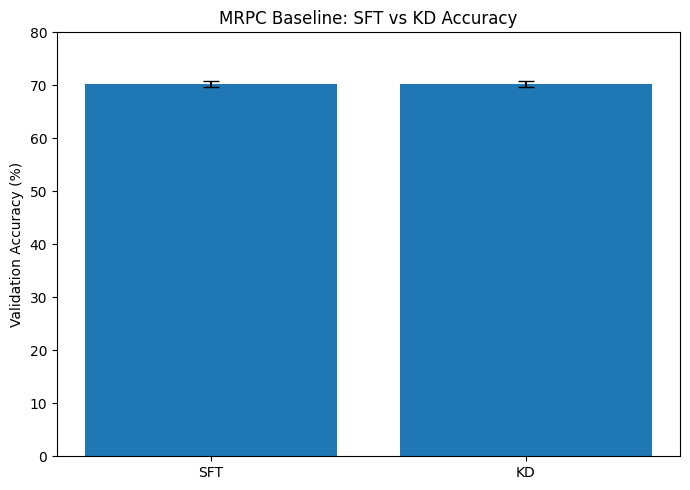

Saved: /content/drive/MyDrive/SLM_Knowledge_Distillation/02_MRPC_Baseline/mrpc_accuracy_comparison.png


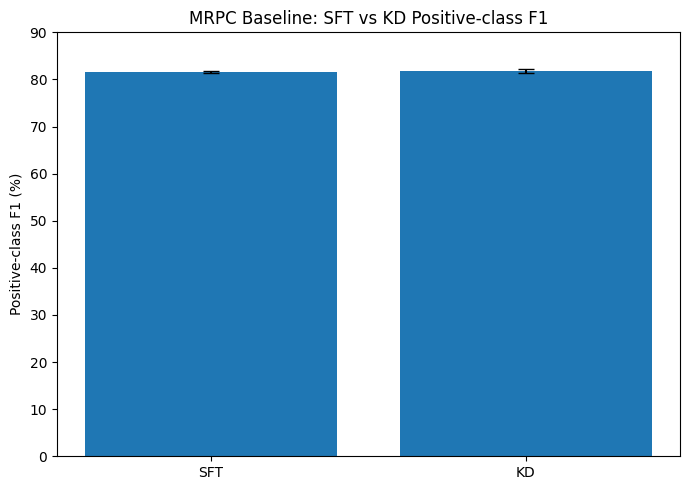

Saved: /content/drive/MyDrive/SLM_Knowledge_Distillation/02_MRPC_Baseline/mrpc_f1_comparison.png


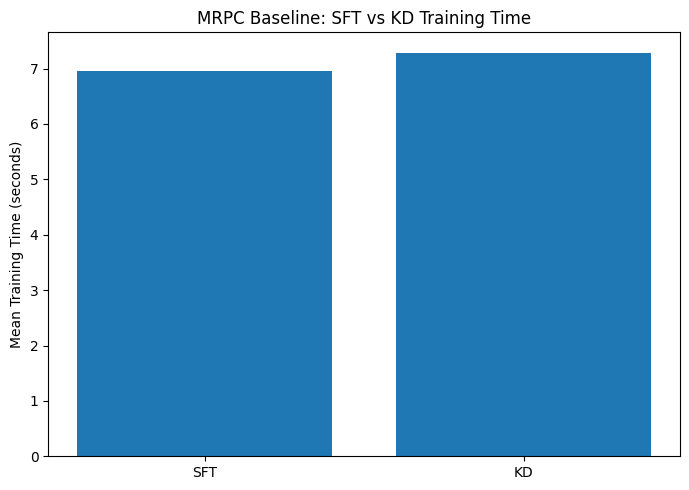

Saved: /content/drive/MyDrive/SLM_Knowledge_Distillation/02_MRPC_Baseline/mrpc_training_time_comparison.png

ALL BASELINE SUMMARY AND GRAPHS SAVED TO:
/content/drive/MyDrive/SLM_Knowledge_Distillation/02_MRPC_Baseline


In [ ]:
# ============================================================
# MRPC BASELINE: SAVE SUMMARY + GENERATE GRAPHS
# SFT vs KD | 3 seeds
# ============================================================

import os
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import drive

# 1. Mount Google Drive
drive.mount("/content/drive")

# 2. Create output folder
SAVE_DIR = (
    "/content/drive/MyDrive/"
    "SLM_Knowledge_Distillation/02_MRPC_Baseline"
)
os.makedirs(SAVE_DIR, exist_ok=True)

# 3. Confirmed three-seed summary values
# Accuracy/F1 values are proportions, not percentages.
summary = pd.DataFrame([
    {
        "method": "SFT",
        "accuracy_mean": 0.7026,
        "accuracy_std": 0.0062,
        "positive_class_f1_mean": 0.8158,
        "positive_class_f1_std": 0.0018,
        "mean_training_seconds": 6.95,
    },
    {
        "method": "KD",
        "accuracy_mean": 0.7026,
        "accuracy_std": 0.0057,
        "positive_class_f1_mean": 0.8184,
        "positive_class_f1_std": 0.0039,
        "mean_training_seconds": 7.29,
    },
])

# Save summary CSV
summary_path = os.path.join(
    SAVE_DIR, "mrpc_baseline_summary.csv"
)
summary.to_csv(summary_path, index=False)

print("Baseline summary saved:", summary_path)
print(summary.to_string(index=False))

# 4. Accuracy graph
plt.figure(figsize=(7, 5))
plt.bar(
    summary["method"],
    summary["accuracy_mean"] * 100,
    yerr=summary["accuracy_std"] * 100,
    capsize=6
)
plt.ylabel("Validation Accuracy (%)")
plt.title("MRPC Baseline: SFT vs KD Accuracy")
plt.ylim(0, 80)
plt.tight_layout()

path = os.path.join(SAVE_DIR, "mrpc_accuracy_comparison.png")
plt.savefig(path, dpi=200, bbox_inches="tight")
plt.show()
plt.close()
print("Saved:", path)

# 5. Positive-class F1 graph
plt.figure(figsize=(7, 5))
plt.bar(
    summary["method"],
    summary["positive_class_f1_mean"] * 100,
    yerr=summary["positive_class_f1_std"] * 100,
    capsize=6
)
plt.ylabel("Positive-class F1 (%)")
plt.title("MRPC Baseline: SFT vs KD Positive-class F1")
plt.ylim(0, 90)
plt.tight_layout()

path = os.path.join(SAVE_DIR, "mrpc_f1_comparison.png")
plt.savefig(path, dpi=200, bbox_inches="tight")
plt.show()
plt.close()
print("Saved:", path)

# 6. Mean training-time graph
plt.figure(figsize=(7, 5))
plt.bar(
    summary["method"],
    summary["mean_training_seconds"]
)
plt.ylabel("Mean Training Time (seconds)")
plt.title("MRPC Baseline: SFT vs KD Training Time")
plt.tight_layout()

path = os.path.join(
    SAVE_DIR, "mrpc_training_time_comparison.png"
)
plt.savefig(path, dpi=200, bbox_inches="tight")
plt.show()
plt.close()
print("Saved:", path)

print("\nALL BASELINE SUMMARY AND GRAPHS SAVED TO:")
print(SAVE_DIR)

Device: cuda
Student: google/bert_uncased_L-2_H-128_A-2
Teacher: textattack/bert-base-uncased-MRPC
Train: 3668
Validation: 408
Test: 1725 (not used)


Tokenizing training data:   0%|          | 0/3668 [00:00<?, ? examples/s]

Tokenizing validation data:   0%|          | 0/408 [00:00<?, ? examples/s]

Teacher parameters: 109483778
Caching teacher logits...
Teacher logits cached: (3668, 2)

Run 1/15: KD_T1_A50, seed=42


Some weights of BertForSequenceClassification were not initialized from the model checkpoint at google/bert_uncased_L-2_H-128_A-2 and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


...


Run 13/15: KD_T2_A75, seed=42
KD_T2_A75 | seed=42 | epoch=1/3 | train_loss=0.7076
KD_T2_A75 | seed=42 | epoch=2/3 | train_loss=0.6568
KD_T2_A75 | seed=42 | epoch=3/3 | train_loss=0.6131


Some weights of BertForSequenceClassification were not initialized from the model checkpoint at google/bert_uncased_L-2_H-128_A-2 and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.



Run 14/15: KD_T2_A75, seed=43
KD_T2_A75 | seed=43 | epoch=1/3 | train_loss=0.7109
KD_T2_A75 | seed=43 | epoch=2/3 | train_loss=0.6708
KD_T2_A75 | seed=43 | epoch=3/3 | train_loss=0.6417


Some weights of BertForSequenceClassification were not initialized from the model checkpoint at google/bert_uncased_L-2_H-128_A-2 and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.



Run 15/15: KD_T2_A75, seed=44
KD_T2_A75 | seed=44 | epoch=1/3 | train_loss=0.7225
KD_T2_A75 | seed=44 | epoch=2/3 | train_loss=0.6675
KD_T2_A75 | seed=44 | epoch=3/3 | train_loss=0.6314

INDIVIDUAL RESULTS
   method  seed  temperature  alpha  epochs  learning_rate  batch_size  max_length  training_seconds  accuracy  f1_positive_class_1  validation_loss
KD_T1_A50    42          1.0   0.50       3        0.00002          16         128         41.064258  0.703431             0.819133         0.582298
KD_T1_A50    43          1.0   0.50       3        0.00002          16         128         11.323427  0.698529             0.813918         0.568683
KD_T1_A50    44          1.0   0.50       3        0.00002          16         128         10.504577  0.703431             0.819672         0.580509
KD_T2_A50    42          2.0   0.50       3        0.00002          16         128         10.562185  0.703431             0.819133         0.621053
KD_T2_A50    43          2.0   0.50       3     

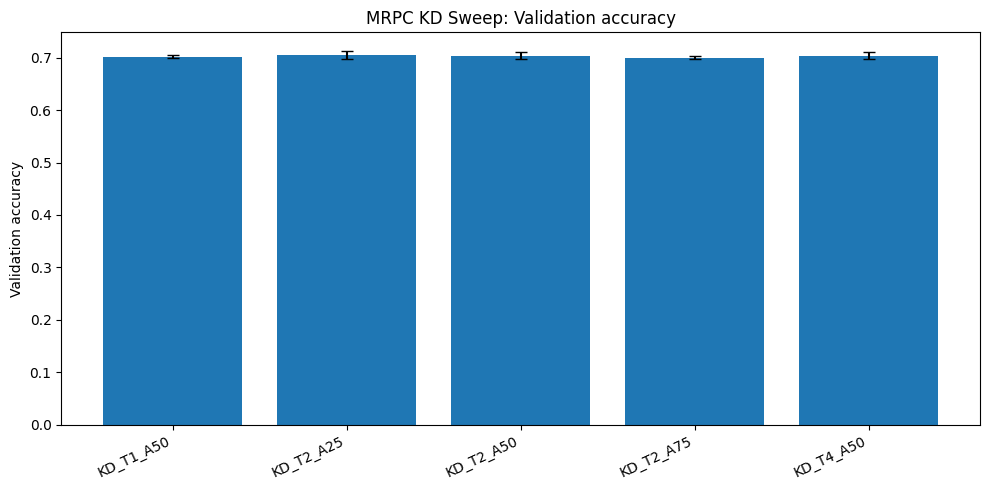

Saved graph: /content/mrpc_kd_sweep_results/mrpc_kd_accuracy.png


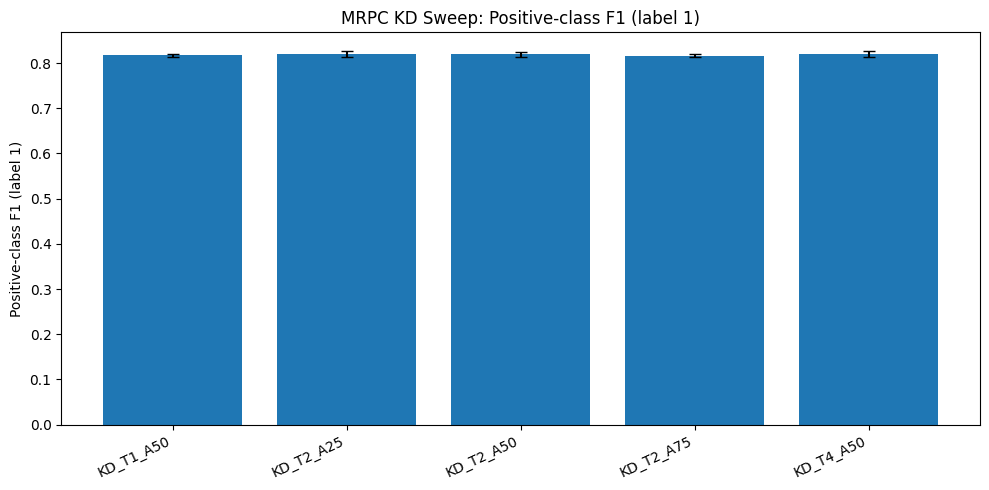

Saved graph: /content/mrpc_kd_sweep_results/mrpc_kd_positive_f1.png

Sweep completed.
Output directory: /content/mrpc_kd_sweep_results
Individual CSV: /content/mrpc_kd_sweep_results/mrpc_kd_individual_results.csv
Summary CSV: /content/mrpc_kd_sweep_results/mrpc_kd_summary_results.csv


In [ ]:
# ============================================================
# MRPC KNOWLEDGE DISTILLATION HYPERPARAMETER SWEEP
# Student: BERT-Tiny (2 layers, hidden size 128)
# Teacher: MRPC-fine-tuned BERT-base
# Dataset: GLUE MRPC
# Seeds: 42, 43, 44
# Outputs: per-run CSV, summary CSV, graphs
# ============================================================

import os
import gc
import json
import random
import time
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

from torch.utils.data import Dataset, DataLoader
from datasets import load_dataset
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from sklearn.metrics import accuracy_score, f1_score

# -------------------- CONFIGURATION --------------------

STUDENT_NAME = "google/bert_uncased_L-2_H-128_A-2"
TEACHER_NAME = "textattack/bert-base-uncased-MRPC"

SEEDS = [42, 43, 44]
EPOCHS = 3
BATCH_SIZE = 16
MAX_LENGTH = 128
LEARNING_RATE = 2e-5

OUTPUT_DIR = "/content/mrpc_kd_sweep_results"
os.makedirs(OUTPUT_DIR, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

SWEEP = [
    {"name": "KD_T1_A50",  "temperature": 1.0, "alpha": 0.50},
    {"name": "KD_T2_A50",  "temperature": 2.0, "alpha": 0.50},
    {"name": "KD_T4_A50",  "temperature": 4.0, "alpha": 0.50},
    {"name": "KD_T2_A25",  "temperature": 2.0, "alpha": 0.25},
    {"name": "KD_T2_A75",  "temperature": 2.0, "alpha": 0.75},
]

print("Device:", DEVICE)
print("Student:", STUDENT_NAME)
print("Teacher:", TEACHER_NAME)

# -------------------- REPRODUCIBILITY --------------------

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

# -------------------- LOAD DATA --------------------

raw = load_dataset("nyu-mll/glue", "mrpc")

train_raw = raw["train"]
val_raw = raw["validation"]

print("Train:", len(train_raw))
print("Validation:", len(val_raw))
print("Test:", len(raw["test"]), "(not used)")

# Verify expected dataset columns before doing expensive work.
required_columns = {"sentence1", "sentence2", "label"}
missing = required_columns - set(train_raw.column_names)

if missing:
    raise ValueError(
        f"MRPC train dataset is missing columns: {missing}. "
        f"Actual columns: {train_raw.column_names}"
    )

if not required_columns.issubset(set(val_raw.column_names)):
    raise ValueError(
        f"Validation columns unexpected: {val_raw.column_names}"
    )

tokenizer = AutoTokenizer.from_pretrained(STUDENT_NAME)

def tokenize_batch(batch):
    return tokenizer(
        batch["sentence1"],
        batch["sentence2"],
        truncation=True,
        padding="max_length",
        max_length=MAX_LENGTH,
    )

train_tok = train_raw.map(
    tokenize_batch,
    batched=True,
    desc="Tokenizing training data"
)

val_tok = val_raw.map(
    tokenize_batch,
    batched=True,
    desc="Tokenizing validation data"
)

# -------------------- PYTORCH DATASET --------------------

class MRPCDataset(Dataset):
    def __init__(self, hf_dataset):
        self.data = hf_dataset

        if "label" not in self.data.column_names:
            raise ValueError(
                "Expected original GLUE column 'label'. "
                f"Found: {self.data.column_names}"
            )

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        row = self.data[idx]

        item = {
            "input_ids": row["input_ids"],
            "attention_mask": row["attention_mask"],
            "labels": int(row["label"]),
            "row_idx": idx,
        }

        if "token_type_ids" in row:
            item["token_type_ids"] = row["token_type_ids"]

        return item

def collate_batch(rows):
    batch = {
        "input_ids": torch.tensor(
            [r["input_ids"] for r in rows], dtype=torch.long
        ),
        "attention_mask": torch.tensor(
            [r["attention_mask"] for r in rows], dtype=torch.long
        ),
        "labels": torch.tensor(
            [r["labels"] for r in rows], dtype=torch.long
        ),
        "row_idx": torch.tensor(
            [r["row_idx"] for r in rows], dtype=torch.long
        ),
    }

    if "token_type_ids" in rows[0]:
        batch["token_type_ids"] = torch.tensor(
            [r["token_type_ids"] for r in rows],
            dtype=torch.long
        )

    return batch

train_ds = MRPCDataset(train_tok)
val_ds = MRPCDataset(val_tok)

# Shuffle training order for each seed; keep validation ordered.
def make_loader(dataset, shuffle=False, seed=42):
    generator = torch.Generator()
    generator.manual_seed(seed)

    return DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        shuffle=shuffle,
        generator=generator if shuffle else None,
        num_workers=0,
        collate_fn=collate_batch,
    )

# -------------------- MODEL INPUTS --------------------

def model_inputs(batch):
    keys = ["input_ids", "attention_mask", "token_type_ids"]
    return {
        k: batch[k].to(DEVICE)
        for k in keys
        if k in batch
    }

# -------------------- LOAD TEACHER --------------------

teacher = AutoModelForSequenceClassification.from_pretrained(
    TEACHER_NAME
).to(DEVICE)

teacher.eval()
for parameter in teacher.parameters():
    parameter.requires_grad = False

teacher_params = sum(p.numel() for p in teacher.parameters())
print("Teacher parameters:", teacher_params)

# -------------------- CACHE TEACHER LOGITS --------------------
# Row indices ensure each teacher logit is matched to its
# corresponding training example, independent of batch order.

print("Caching teacher logits...")

teacher_loader = make_loader(train_ds, shuffle=False)
teacher_logits_cache = torch.empty(
    (len(train_ds), 2), dtype=torch.float32
)

with torch.no_grad():
    for batch in teacher_loader:
        logits = teacher(**model_inputs(batch)).logits.cpu()
        indices = batch["row_idx"]
        teacher_logits_cache[indices] = logits

if teacher_logits_cache.shape != (len(train_ds), 2):
    raise ValueError(
        f"Unexpected teacher-logit shape: {teacher_logits_cache.shape}"
    )

if not torch.isfinite(teacher_logits_cache).all():
    raise ValueError("Teacher logits contain NaN or infinity.")

print("Teacher logits cached:", tuple(teacher_logits_cache.shape))

del teacher
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

# -------------------- EVALUATION --------------------

def evaluate(model):
    model.eval()
    all_labels = []
    all_predictions = []
    total_loss = 0.0
    total_examples = 0

    loader = make_loader(val_ds, shuffle=False)

    with torch.no_grad():
        for batch in loader:
            labels = batch["labels"].to(DEVICE)
            logits = model(**model_inputs(batch)).logits

            loss = F.cross_entropy(logits, labels)

            n = labels.size(0)
            total_loss += loss.item() * n
            total_examples += n

            predictions = logits.argmax(dim=-1)

            all_labels.extend(labels.cpu().tolist())
            all_predictions.extend(predictions.cpu().tolist())

    return {
        "accuracy": accuracy_score(all_labels, all_predictions),
        "f1_positive_class_1": f1_score(
            all_labels, all_predictions,
            pos_label=1, zero_division=0
        ),
        "validation_loss": total_loss / total_examples,
    }

# -------------------- KD TRAINING --------------------

def train_one_kd(config, seed):
    set_seed(seed)

    model = AutoModelForSequenceClassification.from_pretrained(
        STUDENT_NAME,
        num_labels=2,
    ).to(DEVICE)

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=LEARNING_RATE,
    )

    temperature = config["temperature"]
    alpha = config["alpha"]

    start_time = time.perf_counter()

    for epoch in range(EPOCHS):
        model.train()
        running_loss = 0.0
        seen = 0

        train_loader = make_loader(
            train_ds, shuffle=True, seed=seed + epoch
        )

        for batch in train_loader:
            labels = batch["labels"].to(DEVICE)
            row_indices = batch["row_idx"]

            teacher_logits = teacher_logits_cache[
                row_indices
            ].to(DEVICE)

            student_logits = model(
                **model_inputs(batch)
            ).logits

            hard_loss = F.cross_entropy(
                student_logits, labels
            )

            soft_loss = F.kl_div(
                F.log_softmax(
                    student_logits / temperature, dim=-1
                ),
                F.softmax(
                    teacher_logits / temperature, dim=-1
                ),
                reduction="batchmean",
            ) * (temperature ** 2)

            # alpha is the weight of the hard-label CE loss.
            loss = alpha * hard_loss + (1 - alpha) * soft_loss

            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            optimizer.step()

            n = labels.size(0)
            running_loss += loss.item() * n
            seen += n

        print(
            f"{config['name']} | seed={seed} | "
            f"epoch={epoch + 1}/{EPOCHS} | "
            f"train_loss={running_loss / seen:.4f}"
        )

    training_seconds = time.perf_counter() - start_time
    metrics = evaluate(model)

    result = {
        "method": config["name"],
        "seed": seed,
        "temperature": temperature,
        "alpha": alpha,
        "epochs": EPOCHS,
        "learning_rate": LEARNING_RATE,
        "batch_size": BATCH_SIZE,
        "max_length": MAX_LENGTH,
        "training_seconds": training_seconds,
        **metrics,
    }

    del model, optimizer
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return result

# -------------------- RUN SWEEP --------------------

results = []
total_runs = len(SWEEP) * len(SEEDS)
run_number = 0

for config in SWEEP:
    for seed in SEEDS:
        run_number += 1
        print(
            f"\nRun {run_number}/{total_runs}: "
            f"{config['name']}, seed={seed}"
        )

        result = train_one_kd(config, seed)
        results.append(result)

        # Save after every successful run, so progress is retained.
        pd.DataFrame(results).to_csv(
            os.path.join(OUTPUT_DIR, "mrpc_kd_individual_results.csv"),
            index=False,
        )

# -------------------- SUMMARY --------------------

individual = pd.DataFrame(results)

summary = (
    individual.groupby(["method", "temperature", "alpha"])
    .agg(
        accuracy_mean=("accuracy", "mean"),
        accuracy_sd=("accuracy", "std"),
        positive_f1_mean=("f1_positive_class_1", "mean"),
        positive_f1_sd=("f1_positive_class_1", "std"),
        validation_loss_mean=("validation_loss", "mean"),
        training_seconds_mean=("training_seconds", "mean"),
        runs=("seed", "count"),
    )
    .reset_index()
)

individual_path = os.path.join(
    OUTPUT_DIR, "mrpc_kd_individual_results.csv"
)
summary_path = os.path.join(
    OUTPUT_DIR, "mrpc_kd_summary_results.csv"
)

individual.to_csv(individual_path, index=False)
summary.to_csv(summary_path, index=False)

print("\nINDIVIDUAL RESULTS")
print(individual.to_string(index=False))

print("\nSUMMARY RESULTS (mean and sample SD across seeds)")
print(summary.to_string(index=False))

# -------------------- GRAPHS --------------------

def plot_metric(mean_col, sd_col, ylabel, filename):
    x = np.arange(len(summary))
    means = summary[mean_col].to_numpy()
    errors = summary[sd_col].fillna(0).to_numpy()

    plt.figure(figsize=(10, 5))
    plt.bar(x, means, yerr=errors, capsize=4)
    plt.xticks(x, summary["method"], rotation=25, ha="right")
    plt.ylabel(ylabel)
    plt.title(f"MRPC KD Sweep: {ylabel}")
    plt.tight_layout()

    path = os.path.join(OUTPUT_DIR, filename)
    plt.savefig(path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()
    print("Saved graph:", path)

plot_metric(
    "accuracy_mean", "accuracy_sd",
    "Validation accuracy",
    "mrpc_kd_accuracy.png",
)

plot_metric(
    "positive_f1_mean", "positive_f1_sd",
    "Positive-class F1 (label 1)",
    "mrpc_kd_positive_f1.png",
)

# Save configuration and run metadata.
metadata = {
    "dataset": "nyu-mll/glue",
    "dataset_config": "mrpc",
    "student": STUDENT_NAME,
    "teacher": TEACHER_NAME,
    "seeds": SEEDS,
    "epochs": EPOCHS,
    "batch_size": BATCH_SIZE,
    "max_length": MAX_LENGTH,
    "learning_rate": LEARNING_RATE,
    "temperature_alpha_sweep": SWEEP,
    "test_split_used_for_model_selection": False,
    "metric_note": "F1 uses positive class label 1.",
}

with open(
    os.path.join(OUTPUT_DIR, "run_metadata.json"), "w"
) as f:
    json.dump(metadata, f, indent=2)

print("\nSweep completed.")
print("Output directory:", OUTPUT_DIR)
print("Individual CSV:", individual_path)
print("Summary CSV:", summary_path)

In [ ]:
import os
import pandas as pd

folder = "/content/mrpc_kd_sweep"

for filename in ["individual_results.csv", "summary_results.csv"]:
    path = os.path.join(folder, filename)

    if os.path.exists(path):
        print(f"\n--- {filename} ---")
        display(pd.read_csv(path))
    else:
        print(f"NOT FOUND: {path}")

NOT FOUND: /content/mrpc_kd_sweep/individual_results.csv
NOT FOUND: /content/mrpc_kd_sweep/summary_results.csv


In [ ]:
import os

for root, dirs, files in os.walk("/content"):
    for name in files:
        if name.endswith(".csv") and ("mrpc" in name.lower() or "sweep" in name.lower()):
            print(os.path.join(root, name))

/content/mrpc_individual_results.csv
/content/mrpc_mcnemar_seed42.csv
/content/mrpc_summary_results.csv
/content/drive/MyDrive/SLM_Knowledge_Distillation/02_MRPC_Baseline/mrpc_individual_results.csv
/content/drive/MyDrive/SLM_Knowledge_Distillation/02_MRPC_Baseline/mrpc_summary_results.csv
/content/drive/MyDrive/SLM_Knowledge_Distillation/02_MRPC_Baseline/mrpc_mcnemar_seed42.csv
/content/drive/MyDrive/SLM_Knowledge_Distillation/02_MRPC_Baseline/mrpc_baseline_summary.csv
/content/mrpc_kd_sweep_results/mrpc_kd_summary_results.csv
/content/mrpc_kd_sweep_results/mrpc_kd_individual_results.csv


In [ ]:
import pandas as pd
import os

folder = "/content/mrpc_kd_sweep_results"

for filename in [
    "mrpc_kd_summary_results.csv",
    "mrpc_kd_individual_results.csv"
]:
    path = os.path.join(folder, filename)

    print("\n" + "=" * 60)
    print(filename)

    if os.path.exists(path):
        df = pd.read_csv(path)
        display(df)
    else:
        print("File not found:", path)


mrpc_kd_summary_results.csv


,method,temperature,alpha,accuracy_mean,accuracy_sd,positive_f1_mean,positive_f1_sd,validation_loss_mean,training_seconds_mean,runs
0,KD_T1_A50,1.0,0.50,0.701797,0.002830,0.817574,0.003178,0.577163,20.964087,3
1,KD_T2_A25,2.0,0.25,0.705065,0.007879,0.820453,0.006296,0.632614,13.418196,3
2,KD_T2_A50,2.0,0.50,0.704248,0.006168,0.819513,0.005233,0.608737,10.547605,3
3,KD_T2_A75,2.0,0.75,0.700163,0.002830,0.816394,0.002960,0.588149,10.491937,3
4,KD_T4_A50,4.0,0.50,0.704248,0.007488,0.819869,0.005991,0.645172,10.496846,3



mrpc_kd_individual_results.csv


,method,seed,temperature,alpha,epochs,learning_rate,batch_size,max_length,training_seconds,accuracy,f1_positive_class_1,validation_loss
0,KD_T1_A50,42,1.0,0.50,3,0.00002,16,128,41.064258,0.703431,0.819133,0.582298
1,KD_T1_A50,43,1.0,0.50,3,0.00002,16,128,11.323427,0.698529,0.813918,0.568683
2,KD_T1_A50,44,1.0,0.50,3,0.00002,16,128,10.504577,0.703431,0.819672,0.580509
3,KD_T2_A50,42,2.0,0.50,3,0.00002,16,128,10.562185,0.703431,0.819133,0.621053
4,KD_T2_A50,43,2.0,0.50,3,0.00002,16,128,10.570268,0.698529,0.814480,0.583334
5,KD_T2_A50,44,2.0,0.50,3,0.00002,16,128,10.510361,0.710784,0.824926,0.621824
6,KD_T4_A50,42,4.0,0.50,3,0.00002,16,128,10.564764,0.705882,0.821429,0.662560
7,KD_T4_A50,43,4.0,0.50,3,0.00002,16,128,10.501310,0.696078,0.813253,0.610214
8,KD_T4_A50,44,4.0,0.50,3,0.00002,16,128,10.424465,0.710784,0.824926,0.662741
9,KD_T2_A25,42,2.0,0.25,3,0.00002,16,128,13.347492,0.708333,0.823180,0.645824


In [ ]:
import sys
import torch
import torchvision

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)

# Prevent datasets formatter from importing the broken VideoReader
if "torchvision" in sys.modules:
    del sys.modules["torchvision"]

import datasets
datasets.config.TORCHVISION_AVAILABLE = False

print("Fix applied. Now rerun the MRPC T=1.5 cell.")

PyTorch: 2.11.0+cu130
Torchvision: 0.26.0+cu130
Fix applied. Now rerun the MRPC T=1.5 cell.


In [ ]:
# ============================================================
# MRPC: Missing KD configuration T=1.5, alpha=0.4
# Alpha weights KD loss, following the paper's convention.
# Seeds: 42, 43, 44
# Saves to a separate directory; does not overwrite old sweep CSVs.
# ============================================================

import os
import random
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F

from datasets import load_dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    set_seed,
)
from torch.optim import AdamW
from torch.utils.data import DataLoader
from sklearn.metrics import accuracy_score, f1_score

# ---------- Configuration ----------
STUDENT_ID = "google/bert_uncased_L-2-H128_A-2"
TEACHER_ID = "textattack/bert-base-uncased-MRPC"

TEMPERATURE = 1.5
ALPHA = 0.4
SEEDS = [42, 43, 44]
EPOCHS = 3
BATCH_SIZE = 16
MAX_LENGTH = 128
LEARNING_RATE = 2e-5

OUTPUT_DIR = "/content/mrpc_kd_T1.5_A0.4"
os.makedirs(OUTPUT_DIR, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
print("Student:", STUDENT_ID)
print("Teacher:", TEACHER_ID)

# ---------- Load dataset and tokenizers ----------
dataset = load_dataset("nyu-mll/glue", "mrpc")

student_tokenizer = AutoTokenizer.from_pretrained(STUDENT_ID)
teacher_tokenizer = AutoTokenizer.from_pretrained(TEACHER_ID)

def tokenize_dataset(split, tokenizer):
    return split.map(
        lambda batch: tokenizer(
            batch["sentence1"],
            batch["sentence2"],
            truncation=True,
            padding="max_length",
            max_length=MAX_LENGTH,
        ),
        batched=True,
    )

student_data = {
    name: tokenize_dataset(dataset[name], student_tokenizer)
    for name in ["train", "validation"]
}
teacher_train_data = tokenize_dataset(
    dataset["train"], teacher_tokenizer
)

def make_loader(split, shuffle=False):
    split.set_format(
        type="torch",
        columns=["input_ids", "attention_mask", "label"],
    )
    return DataLoader(
        split,
        batch_size=BATCH_SIZE,
        shuffle=shuffle,
    )

# ---------- Cache teacher logits in dataset order ----------
teacher = AutoModelForSequenceClassification.from_pretrained(
    TEACHER_ID
).to(device)
teacher.eval()

teacher_logits_list = []

with torch.no_grad():
    for batch in make_loader(teacher_train_data, shuffle=False):
        inputs = {
            key: batch[key].to(device)
            for key in ["input_ids", "attention_mask"]
        }
        logits = teacher(**inputs).logits
        teacher_logits_list.append(logits.cpu())

teacher_logits = torch.cat(teacher_logits_list, dim=0)

assert len(teacher_logits) == len(student_data["train"]), (
    "Teacher-logit count does not match training dataset."
)

print("Teacher logits cached:", tuple(teacher_logits.shape))

del teacher
if torch.cuda.is_available():
    torch.cuda.empty_cache()

# ---------- Train each seed ----------
results = []

for seed in SEEDS:
    print(f"\n========== Seed {seed} ==========")

    set_seed(seed)
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    student = AutoModelForSequenceClassification.from_pretrained(
        STUDENT_ID,
        num_labels=2,
    ).to(device)

    train_loader = make_loader(
        student_data["train"],
        shuffle=False,
    )

    optimizer = AdamW(
        student.parameters(),
        lr=LEARNING_RATE,
    )

    for epoch in range(EPOCHS):
        student.train()
        total_loss = 0.0
        offset = 0

        for batch in train_loader:
            labels = batch["label"].to(device)
            inputs = {
                key: batch[key].to(device)
                for key in ["input_ids", "attention_mask"]
            }

            batch_size = len(labels)
            teacher_batch_logits = teacher_logits[
                offset:offset + batch_size
            ].to(device)
            offset += batch_size

            optimizer.zero_grad()

            student_logits = student(**inputs).logits

            ce_loss = F.cross_entropy(student_logits, labels)

            kd_loss = F.kl_div(
                F.log_softmax(
                    student_logits / TEMPERATURE,
                    dim=-1,
                ),
                F.softmax(
                    teacher_batch_logits / TEMPERATURE,
                    dim=-1,
                ),
                reduction="batchmean",
            ) * (TEMPERATURE ** 2)

            # Paper convention: alpha weights KD loss.
            loss = (
                ALPHA * kd_loss
                + (1.0 - ALPHA) * ce_loss
            )

            loss.backward()
            optimizer.step()

            total_loss += loss.item()

        print(
            f"Epoch {epoch + 1}/{EPOCHS} | "
            f"mean batch loss: "
            f"{total_loss / len(train_loader):.4f}"
        )

    # ---------- Validation ----------
    student.eval()
    validation_loader = make_loader(
        student_data["validation"],
        shuffle=False,
    )

    predictions = []
    true_labels = []

    with torch.no_grad():
        for batch in validation_loader:
            labels = batch["label"].to(device)

            inputs = {
                key: batch[key].to(device)
                for key in ["input_ids", "attention_mask"]
            }

            logits = student(**inputs).logits
            predicted_labels = logits.argmax(dim=-1)

            predictions.extend(predicted_labels.cpu().tolist())
            true_labels.extend(labels.cpu().tolist())

    accuracy = accuracy_score(true_labels, predictions)
    positive_f1 = f1_score(
        true_labels,
        predictions,
        zero_division=0,
    )

    results.append({
        "method": "KD_T1.5_A0.4",
        "temperature": TEMPERATURE,
        "alpha_kd_weight": ALPHA,
        "seed": seed,
        "accuracy": accuracy,
        "f1_positive_class": positive_f1,
    })

    print(f"Validation accuracy: {accuracy:.4f}")
    print(f"Positive-class F1:    {positive_f1:.4f}")

    # Save each seed's checkpoint separately.
    checkpoint_dir = os.path.join(
        OUTPUT_DIR, f"seed_{seed}"
    )
    student.save_pretrained(checkpoint_dir)
    student_tokenizer.save_pretrained(checkpoint_dir)

    del student
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

# ---------- Save results separately ----------
individual = pd.DataFrame(results)

individual_path = os.path.join(
    OUTPUT_DIR, "individual_results.csv"
)
individual.to_csv(individual_path, index=False)

summary = individual[
    ["accuracy", "f1_positive_class"]
].agg(["mean", "std"]).T

summary_path = os.path.join(
    OUTPUT_DIR, "summary_results.csv"
)
summary.to_csv(summary_path)

print("\n========== Individual results ==========")
display(individual)

print("\n========== Mean and sample SD ==========")
display(summary)

print("\nSaved individual results:", individual_path)
print("Saved summary:", summary_path)

Device: cuda
Student: google/bert_uncased_L-2-H128_A-2
Teacher: textattack/bert-base-uncased-MRPC


OSError: google/bert_uncased_L-2-H128_A-2 is not a local folder and is not a valid model identifier listed on 'https://huggingface.co/models'
If this is a private repository, make sure to pass a token having permission to this repo either by logging in with `hf auth login` or by passing `token=<your_token>`

In [ ]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification

STUDENT_ID = "google/bert_uncased_L-2_H-128_A-2"

tokenizer = AutoTokenizer.from_pretrained(STUDENT_ID)
model = AutoModelForSequenceClassification.from_pretrained(
    STUDENT_ID,
    num_labels=2
)

print("Student tokenizer and model loaded successfully!")
print("Parameters:", sum(p.numel() for p in model.parameters()))

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at google/bert_uncased_L-2_H-128_A-2 and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Student tokenizer and model loaded successfully!
Parameters: 4386178


In [ ]:
# ============================================================
# MRPC Knowledge Distillation: T=1.5, alpha=0.4
# Correct student ID verified by successful model loading.
# Alpha = KD-loss weight, following the paper convention.
# Seeds: 42, 43, 44
# Saves results separately from the existing sweep.
# ============================================================

import os
import random
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F

from datasets import load_dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    set_seed,
)
from torch.optim import AdamW
from torch.utils.data import DataLoader
from sklearn.metrics import accuracy_score, f1_score

# ---------- Configuration ----------
STUDENT_ID = "google/bert_uncased_L-2_H-128_A-2"
TEACHER_ID = "textattack/bert-base-uncased-MRPC"

TEMPERATURE = 1.5
ALPHA = 0.4                 # KD loss weight
SEEDS = [42, 43, 44]
EPOCHS = 3
BATCH_SIZE = 16
MAX_LENGTH = 128
LEARNING_RATE = 2e-5

OUTPUT_DIR = "/content/mrpc_kd_T1.5_A0.4"
os.makedirs(OUTPUT_DIR, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
print("Student:", STUDENT_ID)
print("Teacher:", TEACHER_ID)

# ---------- Load dataset ----------
dataset = load_dataset("nyu-mll/glue", "mrpc")

student_tokenizer = AutoTokenizer.from_pretrained(STUDENT_ID)
teacher_tokenizer = AutoTokenizer.from_pretrained(TEACHER_ID)

def tokenize_split(split, tokenizer):
    return split.map(
        lambda batch: tokenizer(
            batch["sentence1"],
            batch["sentence2"],
            truncation=True,
            padding="max_length",
            max_length=MAX_LENGTH,
        ),
        batched=True,
    )

student_train = tokenize_split(dataset["train"], student_tokenizer)
student_val = tokenize_split(dataset["validation"], student_tokenizer)
teacher_train = tokenize_split(dataset["train"], teacher_tokenizer)

def make_loader(split, shuffle=False):
    split.set_format(
        type="torch",
        columns=["input_ids", "attention_mask", "label"],
    )
    return DataLoader(
        split,
        batch_size=BATCH_SIZE,
        shuffle=shuffle,
    )

# ---------- Cache teacher logits ----------
teacher = AutoModelForSequenceClassification.from_pretrained(
    TEACHER_ID
).to(device)
teacher.eval()

teacher_logits_parts = []

with torch.no_grad():
    for batch in make_loader(teacher_train, shuffle=False):
        inputs = {
            key: batch[key].to(device)
            for key in ["input_ids", "attention_mask"]
        }
        teacher_logits_parts.append(
            teacher(**inputs).logits.cpu()
        )

teacher_logits = torch.cat(teacher_logits_parts, dim=0)

assert teacher_logits.shape[0] == len(student_train), (
    "Teacher logits do not match the training-set size."
)
assert teacher_logits.shape[1] == 2, (
    "Expected teacher to produce two class logits."
)

print("Teacher logits cached:", tuple(teacher_logits.shape))

del teacher
if torch.cuda.is_available():
    torch.cuda.empty_cache()

# ---------- Train each seed ----------
results = []

for seed in SEEDS:
    print(f"\n========== Seed {seed} ==========")

    set_seed(seed)
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    student = AutoModelForSequenceClassification.from_pretrained(
        STUDENT_ID,
        num_labels=2,
    ).to(device)

    train_loader = make_loader(student_train, shuffle=False)
    optimizer = AdamW(
        student.parameters(),
        lr=LEARNING_RATE,
    )

    for epoch in range(EPOCHS):
        student.train()
        total_loss = 0.0
        offset = 0

        for batch in train_loader:
            labels = batch["label"].to(device)
            inputs = {
                key: batch[key].to(device)
                for key in ["input_ids", "attention_mask"]
            }

            n = len(labels)
            teacher_batch_logits = teacher_logits[
                offset:offset + n
            ].to(device)
            offset += n

            optimizer.zero_grad()
            student_logits = student(**inputs).logits

            ce_loss = F.cross_entropy(student_logits, labels)

            kd_loss = F.kl_div(
                F.log_softmax(
                    student_logits / TEMPERATURE,
                    dim=-1,
                ),
                F.softmax(
                    teacher_batch_logits / TEMPERATURE,
                    dim=-1,
                ),
                reduction="batchmean",
            ) * (TEMPERATURE ** 2)

            # Paper convention: alpha weights KD loss.
            loss = (
                ALPHA * kd_loss
                + (1.0 - ALPHA) * ce_loss
            )

            loss.backward()
            optimizer.step()
            total_loss += loss.item()

        print(
            f"Epoch {epoch + 1}/{EPOCHS} | "
            f"mean batch loss: "
            f"{total_loss / len(train_loader):.4f}"
        )

    # ---------- Validation ----------
    student.eval()
    val_loader = make_loader(student_val, shuffle=False)

    predictions = []
    true_labels = []

    with torch.no_grad():
        for batch in val_loader:
            labels = batch["label"].to(device)
            inputs = {
                key: batch[key].to(device)
                for key in ["input_ids", "attention_mask"]
            }

            logits = student(**inputs).logits
            predictions.extend(
                logits.argmax(dim=-1).cpu().tolist()
            )
            true_labels.extend(labels.cpu().tolist())

    accuracy = accuracy_score(true_labels, predictions)
    positive_f1 = f1_score(
        true_labels,
        predictions,
        zero_division=0,
    )

    results.append({
        "method": "KD_T1.5_A0.4",
        "temperature": TEMPERATURE,
        "alpha_kd_weight": ALPHA,
        "seed": seed,
        "accuracy": accuracy,
        "f1_positive_class": positive_f1,
    })

    print(f"Validation accuracy: {accuracy:.4f}")
    print(f"Positive-class F1: {positive_f1:.4f}")

    checkpoint_dir = os.path.join(OUTPUT_DIR, f"seed_{seed}")
    student.save_pretrained(checkpoint_dir)
    student_tokenizer.save_pretrained(checkpoint_dir)

    del student
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

# ---------- Save new results separately ----------
individual = pd.DataFrame(results)

individual_path = os.path.join(
    OUTPUT_DIR, "individual_results.csv"
)
individual.to_csv(individual_path, index=False)

summary = individual[
    ["accuracy", "f1_positive_class"]
].agg(["mean", "std"]).T

summary_path = os.path.join(
    OUTPUT_DIR, "summary_results.csv"
)
summary.to_csv(summary_path)

print("\n========== Individual results ==========")
display(individual)

print("\n========== Mean and sample SD ==========")
display(summary)

print("\nSaved individual results:", individual_path)
print("Saved summary:", summary_path)

Device: cuda
Student: google/bert_uncased_L-2_H-128_A-2
Teacher: textattack/bert-base-uncased-MRPC


Map:   0%|          | 0/408 [00:00<?, ? examples/s]

Teacher logits cached: (3668, 2)

========== Seed 42 ==========


Some weights of BertForSequenceClassification were not initialized from the model checkpoint at google/bert_uncased_L-2_H-128_A-2 and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Epoch 1/3 | mean batch loss: 0.5354
Epoch 2/3 | mean batch loss: 0.5184
Epoch 3/3 | mean batch loss: 0.5064
Validation accuracy: 0.5882
Positive-class F1: 0.6410

========== Seed 43 ==========


...

Epoch 1/3 | mean batch loss: 0.5366
Epoch 2/3 | mean batch loss: 0.5213
Epoch 3/3 | mean batch loss: 0.5115
Validation accuracy: 0.6054
Positive-class F1: 0.6708

========== Individual results ==========


,method,temperature,alpha_kd_weight,seed,accuracy,f1_positive_class
0,KD_T1.5_A0.4,1.5,0.4,42,0.588235,0.641026
1,KD_T1.5_A0.4,1.5,0.4,43,0.612745,0.677551
2,KD_T1.5_A0.4,1.5,0.4,44,0.605392,0.670757



========== Mean and sample SD ==========


,mean,std
accuracy,0.602124,0.012577
f1_positive_class,0.663111,0.019426



Saved individual results: /content/mrpc_kd_T1.5_A0.4/individual_results.csv
Saved summary: /content/mrpc_kd_T1.5_A0.4/summary_results.csv


In [ ]:
from transformers import AutoConfig

TEACHER_ID = "textattack/bert-base-uncased-MRPC"

cfg = AutoConfig.from_pretrained(TEACHER_ID)

print("Teacher id2label:", cfg.id2label)
print("Teacher label2id:", cfg.label2id)
print("MRPC dataset labels:", dataset["train"].features["label"])
print("MRPC label names:", dataset["train"].features["label"].names)

Teacher id2label: {0: 'LABEL_0', 1: 'LABEL_1'}
Teacher label2id: {'LABEL_0': 0, 'LABEL_1': 1}
MRPC dataset labels: ClassLabel(names=['not_equivalent', 'equivalent'], id=None)
MRPC label names: ['not_equivalent', 'equivalent']


In [ ]:
import torch
from datasets import load_dataset
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from torch.utils.data import DataLoader
from sklearn.metrics import accuracy_score

TEACHER_ID = "textattack/bert-base-uncased-MRPC"
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

ds = load_dataset("nyu-mll/glue", "mrpc")
val = ds["validation"]

tokenizer = AutoTokenizer.from_pretrained(TEACHER_ID)
teacher = AutoModelForSequenceClassification.from_pretrained(
    TEACHER_ID
).to(device)
teacher.eval()

def tokenize(batch):
    return tokenizer(
        batch["sentence1"],
        batch["sentence2"],
        truncation=True,
        padding="max_length",
        max_length=128,
    )

val_tok = val.map(tokenize, batched=True)
val_tok.set_format(
    type="torch",
    columns=["input_ids", "attention_mask", "label"],
)
loader = DataLoader(val_tok, batch_size=16, shuffle=False)

preds, labels = [], []

with torch.no_grad():
    for batch in loader:
        inputs = {
            k: batch[k].to(device)
            for k in ["input_ids", "attention_mask"]
        }
        predictions = teacher(**inputs).logits.argmax(dim=-1)
        preds.extend(predictions.cpu().tolist())
        labels.extend(batch["label"].tolist())

print("Teacher accuracy, normal label order:",
      round(accuracy_score(labels, preds), 4))
print("Teacher accuracy, flipped label order:",
      round(accuracy_score(labels, [1-p for p in preds]), 4))

print("Dataset label counts:", {
    0: labels.count(0),
    1: labels.count(1)
})
print("Teacher prediction counts:", {
    0: preds.count(0),
    1: preds.count(1)
})

Map:   0%|          | 0/408 [00:00<?, ? examples/s]

Teacher accuracy, normal label order: 0.4632
Teacher accuracy, flipped label order: 0.5368
Dataset label counts: {0: 129, 1: 279}
Teacher prediction counts: {0: 344, 1: 64}


In [ ]:
import torch
from datasets import load_dataset
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from torch.utils.data import DataLoader
from sklearn.metrics import accuracy_score, f1_score

MODEL_ID = "textattack/bert-base-uncased-MRPC"
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

ds_check = load_dataset("nyu-mll/glue", "mrpc")
val_check = ds_check["validation"]

tok = AutoTokenizer.from_pretrained(MODEL_ID)
mdl = AutoModelForSequenceClassification.from_pretrained(
    MODEL_ID
).to(device)
mdl.eval()

def encode(batch):
    return tok(
        batch["sentence1"],
        batch["sentence2"],
        truncation=True,
        padding="max_length",
        max_length=256,
    )

val_check = val_check.map(encode, batched=True)
val_check.set_format(
    type="torch",
    columns=["input_ids", "attention_mask", "label"],
)
loader = DataLoader(val_check, batch_size=16, shuffle=False)

preds, labels = [], []

with torch.no_grad():
    for batch in loader:
        x = {
            k: batch[k].to(device)
            for k in ["input_ids", "attention_mask"]
        }
        logits = mdl(**x).logits
        preds.extend(logits.argmax(-1).cpu().tolist())
        labels.extend(batch["label"].tolist())

print("Accuracy:", round(accuracy_score(labels, preds), 4))
print("Positive-class F1:", round(f1_score(labels, preds, zero_division=0), 4))
print("Prediction counts:", {0: preds.count(0), 1: preds.count(1)})
print("Dataset counts:", {0: labels.count(0), 1: labels.count(1)})

Map:   0%|          | 0/408 [00:00<?, ? examples/s]

Accuracy: 0.4632
Positive-class F1: 0.3615
Prediction counts: {0: 344, 1: 64}
Dataset counts: {0: 129, 1: 279}


In [ ]:
import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from datasets import load_dataset

model_id = "textattack/bert-base-uncased-MRPC"
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

ds = load_dataset("nyu-mll/glue", "mrpc")
tok = AutoTokenizer.from_pretrained(model_id)
model = AutoModelForSequenceClassification.from_pretrained(model_id).to(device)
model.eval()

# Print model configuration and predictions for 10 examples
print("Model:", model_id)
print("Number of labels:", model.config.num_labels)
print("Classifier weight shape:", tuple(model.classifier.weight.shape))

examples = ds["validation"].select(range(10))

inputs = tok(
    examples["sentence1"],
    examples["sentence2"],
    truncation=True,
    padding=True,
    max_length=256,
    return_tensors="pt",
).to(device)

with torch.no_grad():
    logits = model(**inputs).logits
    probs = torch.softmax(logits, dim=-1)
    preds = logits.argmax(dim=-1).cpu().tolist()

for i in range(10):
    print(
        f"\nExample {i+1}",
        f"\nTrue label: {examples[i]['label']}",
        f"\nPredicted label: {preds[i]}",
        f"\nProbabilities: {probs[i].cpu().tolist()}",
        f"\nSentence 1: {examples[i]['sentence1'][:100]}",
        f"\nSentence 2: {examples[i]['sentence2'][:100]}",
    )

Model: textattack/bert-base-uncased-MRPC
Number of labels: 2
Classifier weight shape: (2, 768)

Example 1 
True label: 1 
Predicted label: 1 
Probabilities: [0.005539047997444868, 0.994460940361023] 
Sentence 1: He said the foodservice pie business doesn 't fit the company 's long-term growth strategy . 
Sentence 2: " The foodservice pie business does not fit our long-term growth strategy .

Example 2 
True label: 0 
Predicted label: 0 
Probabilities: [0.9436206221580505, 0.056379422545433044] 
Sentence 1: Magnarelli said Racicot hated the Iraqi regime and looked forward to using his long years of trainin 
Sentence 2: His wife said he was " 100 percent behind George Bush " and looked forward to using his years of tra

Example 3 
True label: 0 
Predicted label: 0 
Probabilities: [0.7156803011894226, 0.2843196988105774] 
Sentence 1: The dollar was at 116.92 yen against the yen , flat on the session , and at 1.2891 against the Swiss 
Sentence 2: The dollar was at 116.78 yen JPY = , virtua

In [ ]:
from collections import Counter
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix
import numpy as np

# These variables should come from your existing
# teacher validation evaluation.
print("Validation labels:", Counter(y_true))
print("Teacher predictions:", Counter(y_pred))

print("Accuracy:", accuracy_score(y_true, y_pred))
print("Positive-class F1:", f1_score(y_true, y_pred, pos_label=1))
print("Confusion matrix:")
print(confusion_matrix(y_true, y_pred))

Validation labels: Counter({np.int64(1): 279, np.int64(0): 129})
Teacher predictions: Counter({np.int64(1): 389, np.int64(0): 19})
Accuracy: 0.7058823529411765
Positive-class F1: 0.8203592814371258
Confusion matrix:
[[ 14 115]
 [  5 274]]


In [ ]:
# Find the notebook cell where these variables are assigned.
# Search your notebook for:
# y_true =
# y_pred =
# predictions =
# compute_metrics

In [ ]:
print("y_true exists:", "y_true" in globals())
print("y_pred exists:", "y_pred" in globals())

print("Available prediction-related variables:")
for name in globals():
    if any(word in name.lower() for word in
           ["teacher", "student", "pred", "label", "logit"]):
        print(name)

y_true exists: True
y_pred exists: True
Available prediction-related variables:
STUDENT_NAME
TEACHER_NAME
cache_teacher_logits
teacher_train_logits
teacher_val_logits
teacher_acc
teacher_f1
predictions_seed42
pred_data
sft_pred
kd_pred
y_pred
TEACHER_BATCH_SIZE
teacher_loader
teacher_logits_parts
teacher_params
teacher_logits_cache
logits
STUDENT_ID
TEACHER_ID
student_tokenizer
teacher_tokenizer
student_data
teacher_data
teacher_train
teacher_logits_all
student_train
student_val
teacher_logits
labels
teacher_batch_logits
student_logits
predictions
true_labels
teacher
preds


In [ ]:
import numpy as np
from collections import Counter
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

print("=== MRPC DIAGNOSTIC ===")

# Inspect the existing teacher validation logits
if "teacher_val_logits" in globals():
    tl = np.asarray(teacher_val_logits)
    print("teacher_val_logits shape:", tl.shape)

    if tl.ndim == 2 and tl.shape[1] == 2:
        print("Teacher predictions:", Counter(tl.argmax(axis=1)))
    else:
        print("Teacher logits are not in expected (N, 2) shape.")
else:
    print("teacher_val_logits not found.")

# Inspect possible existing validation-label sources
for name in ["teacher_val", "student_val", "true_labels", "labels"]:
    if name not in globals():
        continue

    obj = globals()[name]
    print(f"\n{name}: type={type(obj).__name__}")

    try:
        if hasattr(obj, "column_names"):
            print("columns:", obj.column_names)
            for col in ["labels", "label"]:
                if col in obj.column_names:
                    print(col, "count:", Counter(obj[col]))
                    break
        else:
            arr = np.asarray(obj)
            print("shape:", arr.shape)
    except Exception as e:
        print("Inspection note:", str(e))

print("\nExisting teacher_acc:", globals().get("teacher_acc", "not found"))
print("Existing teacher_f1:", globals().get("teacher_f1", "not found"))

=== MRPC DIAGNOSTIC ===
teacher_val_logits shape: (408, 2)
Teacher predictions: Counter({np.int64(1): 299, np.int64(0): 109})

student_val: type=Dataset
columns: ['sentence1', 'sentence2', 'label', 'idx', 'input_ids', 'token_type_ids', 'attention_mask']
label count: Counter({tensor(1): 1, tensor(0): 1, tensor(0): 1, tensor(1): 1, tensor(0): 1, tensor(1): 1, tensor(0): 1, tensor(1): 1, tensor(1): 1, tensor(1): 1, tensor(1): 1, tensor(0): 1, tensor(0): 1, tensor(1): 1, tensor(1): 1, tensor(1): 1, tensor(1): 1, tensor(0): 1, tensor(1): 1, tensor(0): 1, tensor(0): 1, tensor(1): 1, tensor(0): 1, tensor(1): 1, tensor(1): 1, tensor(1): 1, tensor(0): 1, tensor(1): 1, tensor(1): 1, tensor(1): 1, tensor(0): 1, tensor(1): 1, tensor(1): 1, tensor(1): 1, tensor(1): 1, tensor(0): 1, tensor(0): 1, tensor(0): 1, tensor(1): 1, tensor(1): 1, tensor(0): 1, tensor(1): 1, tensor(0): 1, tensor(0): 1, tensor(0): 1, tensor(1): 1, tensor(1): 1, tensor(0): 1, tensor(1): 1, tensor(1): 1, tensor(1): 1, tensor(1):

In [ ]:
import numpy as np
from collections import Counter
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

y = np.asarray(student_val["label"], dtype=int)
p = np.asarray(teacher_val_logits).argmax(axis=1)

print("Label count:", Counter(y))
print("Teacher prediction count:", Counter(p))
print("Label length:", len(y))
print("Prediction length:", len(p))

if len(y) == len(p):
    print("Accuracy:", accuracy_score(y, p))
    print("Positive-class F1:", f1_score(y, p, pos_label=1))
    print("Confusion matrix:\n", confusion_matrix(y, p))
else:
    print("Mismatch: labels and predictions have different lengths.")

Label count: Counter({np.int64(1): 279, np.int64(0): 129})
Teacher prediction count: Counter({np.int64(1): 299, np.int64(0): 109})
Label length: 408
Prediction length: 408
Accuracy: 0.8774509803921569
Positive-class F1: 0.9134948096885813
Confusion matrix:
 [[ 94  35]
 [ 15 264]]


In [ ]:
import numpy as np
from sklearn.metrics import accuracy_score, f1_score

y = np.asarray(student_val["label"], dtype=int)

for name in ["sft_pred", "kd_pred"]:
    if name not in globals():
        print(name, "not found")
        continue

    p = np.asarray(globals()[name]).reshape(-1)

    print(f"\n{name}")
    print("Prediction count:", len(p))

    if len(p) == len(y):
        print("Accuracy:", accuracy_score(y, p))
        print("Positive-class F1:", f1_score(y, p, pos_label=1))
    else:
        print("Cannot compare: prediction length differs from labels.")


sft_pred
Prediction count: 408
Accuracy: 0.7034313725490197
Positive-class F1: 0.8163884673748103

kd_pred
Prediction count: 408
Accuracy: 0.7058823529411765
Positive-class F1: 0.8203592814371258


In [ ]:
import os

paths = [
    "/content/mrpc_individual_results.csv",
    "/content/mrpc_summary_results.csv",
    "/content/mrpc_kd_sweep_results/mrpc_kd_individual_results.csv",
    "/content/mrpc_kd_sweep_results/mrpc_kd_summary_results.csv",
]

for path in paths:
    print(("FOUND  " if os.path.exists(path) else "MISSING"), path)

FOUND   /content/mrpc_individual_results.csv
FOUND   /content/mrpc_summary_results.csv
FOUND   /content/mrpc_kd_sweep_results/mrpc_kd_individual_results.csv
FOUND   /content/mrpc_kd_sweep_results/mrpc_kd_summary_results.csv


In [ ]:
import os
import pandas as pd

paths = [
    "/content/mrpc_individual_results.csv",
    "/content/mrpc_summary_results.csv",
    "/content/mrpc_kd_sweep_results/mrpc_kd_individual_results.csv",
    "/content/mrpc_kd_sweep_results/mrpc_kd_summary_results.csv",
]

for path in paths:
    print("\n" + "=" * 60)
    print(path)

    if os.path.exists(path):
        df = pd.read_csv(path)
        print("Shape:", df.shape)
        print("Columns:", df.columns.tolist())
        display(df.head(5))
    else:
        print("FILE NOT FOUND")


/content/mrpc_individual_results.csv
Shape: (6, 5)
Columns: ['seed', 'method', 'accuracy', 'f1', 'training_seconds']


,seed,method,accuracy,f1,training_seconds
0,42,SFT,0.703431,0.816388,7.060523
1,42,KD,0.705882,0.820359,7.318089
2,43,SFT,0.708333,0.817204,6.866373
3,43,KD,0.696078,0.813814,7.256343
4,44,SFT,0.696078,0.813814,6.927695



/content/mrpc_summary_results.csv
Shape: (2, 6)
Columns: ['method', 'accuracy_mean', 'accuracy_std', 'f1_mean', 'f1_std', 'mean_training_seconds']


,method,accuracy_mean,accuracy_std,f1_mean,f1_std,mean_training_seconds
0,KD,0.702614,0.005660,0.818356,0.003943,7.290855
1,SFT,0.702614,0.006168,0.815802,0.001770,6.951530



/content/mrpc_kd_sweep_results/mrpc_kd_individual_results.csv
Shape: (15, 12)
Columns: ['method', 'seed', 'temperature', 'alpha', 'epochs', 'learning_rate', 'batch_size', 'max_length', 'training_seconds', 'accuracy', 'f1_positive_class_1', 'validation_loss']


,method,seed,temperature,alpha,epochs,learning_rate,batch_size,max_length,training_seconds,accuracy,f1_positive_class_1,validation_loss
0,KD_T1_A50,42,1.0,0.5,3,0.00002,16,128,41.064258,0.703431,0.819133,0.582298
1,KD_T1_A50,43,1.0,0.5,3,0.00002,16,128,11.323427,0.698529,0.813918,0.568683
2,KD_T1_A50,44,1.0,0.5,3,0.00002,16,128,10.504577,0.703431,0.819672,0.580509
3,KD_T2_A50,42,2.0,0.5,3,0.00002,16,128,10.562185,0.703431,0.819133,0.621053
4,KD_T2_A50,43,2.0,0.5,3,0.00002,16,128,10.570268,0.698529,0.814480,0.583334



/content/mrpc_kd_sweep_results/mrpc_kd_summary_results.csv
Shape: (5, 10)
Columns: ['method', 'temperature', 'alpha', 'accuracy_mean', 'accuracy_sd', 'positive_f1_mean', 'positive_f1_sd', 'validation_loss_mean', 'training_seconds_mean', 'runs']


,method,temperature,alpha,accuracy_mean,accuracy_sd,positive_f1_mean,positive_f1_sd,validation_loss_mean,training_seconds_mean,runs
0,KD_T1_A50,1.0,0.50,0.701797,0.002830,0.817574,0.003178,0.577163,20.964087,3
1,KD_T2_A25,2.0,0.25,0.705065,0.007879,0.820453,0.006296,0.632614,13.418196,3
2,KD_T2_A50,2.0,0.50,0.704248,0.006168,0.819513,0.005233,0.608737,10.547605,3
3,KD_T2_A75,2.0,0.75,0.700163,0.002830,0.816394,0.002960,0.588149,10.491937,3
4,KD_T4_A50,4.0,0.50,0.704248,0.007488,0.819869,0.005991,0.645172,10.496846,3


In [ ]:
import pandas as pd

files = {
    "baseline_individual": "/content/mrpc_individual_results.csv",
    "baseline_summary": "/content/mrpc_summary_results.csv",
    "sweep_individual": "/content/mrpc_kd_sweep_results/mrpc_kd_individual_results.csv",
    "sweep_summary": "/content/mrpc_kd_sweep_results/mrpc_kd_summary_results.csv",
}

for name, path in files.items():
    print("\n###", name)
    df = pd.read_csv(path)
    print(df.to_string(index=False))


### baseline_individual
 seed method  accuracy       f1  training_seconds
   42    SFT  0.703431 0.816388          7.060523
   42     KD  0.705882 0.820359          7.318089
   43    SFT  0.708333 0.817204          6.866373
   43     KD  0.696078 0.813814          7.256343
   44    SFT  0.696078 0.813814          6.927695
   44     KD  0.705882 0.820896          7.298132

### baseline_summary
method  accuracy_mean  accuracy_std  f1_mean   f1_std  mean_training_seconds
    KD       0.702614      0.005660 0.818356 0.003943               7.290855
   SFT       0.702614      0.006168 0.815802 0.001770               6.951530

### sweep_individual
   method  seed  temperature  alpha  epochs  learning_rate  batch_size  max_length  training_seconds  accuracy  f1_positive_class_1  validation_loss
KD_T1_A50    42          1.0   0.50       3        0.00002          16         128         41.064258  0.703431             0.819133         0.582298
KD_T1_A50    43          1.0   0.50       3        0

In [ ]:
# Safe check: inspect existing variables; no training or changes
keywords = [
    "train", "val", "teacher", "student",
    "token", "logit", "model", "dataset"
]

for name, obj in sorted(globals().items()):
    if any(k in name.lower() for k in keywords):
        if not name.startswith("_"):
            try:
                shape = getattr(obj, "shape", None)
                length = len(obj) if not isinstance(obj, type) else None
                print(f"{name}: type={type(obj).__name__}, "
                      f"shape={shape}, length={length}")
            except Exception:
                print(f"{name}: type={type(obj).__name__}")

AutoModelForSequenceClassification: type=type, shape=None, length=None
AutoTokenizer: type=type, shape=None, length=None
DATASET_CONFIG: type=str, shape=None, length=4
DATASET_NAME: type=str, shape=None, length=12
Dataset: type=type, shape=None, length=None
IndexedDataset: type=type, shape=None, length=None
MODEL_ID: type=str, shape=None, length=33
MRPCDataset: type=type, shape=None, length=None
STUDENT_ID: type=str, shape=None, length=33
STUDENT_NAME: type=str, shape=None, length=33
TEACHER_BATCH_SIZE: type=int
TEACHER_ID: type=str, shape=None, length=33
TEACHER_NAME: type=str, shape=None, length=33
TensorDataset: type=type, shape=None, length=None
cache_teacher_logits: type=function
dataset: type=DatasetDict, shape={'train': (3668, 4), 'validation': (408, 4), 'test': (1725, 4)}, length=3
datasets: type=module
evaluate: type=function
evaluate_mrpc: type=function
load_dataset: type=function
logits: type=Tensor, shape=torch.Size([10, 2]), length=10
model: type=BertForSequenceClassificat

In [ ]:
import inspect

for name in ["train_one_kd", "train_kd_run", "evaluate_mrpc"]:
    fn = globals().get(name)
    print(f"\n{'=' * 25} {name} {'=' * 25}")

    if callable(fn):
        try:
            print("Signature:", inspect.signature(fn))
            print(inspect.getsource(fn))
        except (OSError, TypeError) as e:
            print("Source unavailable:", e)
    else:
        print("Function not found.")


========================= train_one_kd =========================
Signature: (config, seed)
def train_one_kd(config, seed):
    set_seed(seed)

    model = AutoModelForSequenceClassification.from_pretrained(
        STUDENT_NAME,
        num_labels=2,
    ).to(DEVICE)

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=LEARNING_RATE,
    )

    temperature = config["temperature"]
    alpha = config["alpha"]

    start_time = time.perf_counter()

    for epoch in range(EPOCHS):
        model.train()
        running_loss = 0.0
        seen = 0

        train_loader = make_loader(
            train_ds, shuffle=True, seed=seed + epoch
        )

        for batch in train_loader:
            labels = batch["labels"].to(DEVICE)
            row_indices = batch["row_idx"]

            teacher_logits = teacher_logits_cache[
                row_indices
            ].to(DEVICE)

            student_logits = model(
                **model_inputs(batch)
            ).logits


In [ ]:
import inspect

print(inspect.getsource(train_one_kd))

def train_one_kd(config, seed):
    set_seed(seed)

    model = AutoModelForSequenceClassification.from_pretrained(
        STUDENT_NAME,
        num_labels=2,
    ).to(DEVICE)

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=LEARNING_RATE,
    )

    temperature = config["temperature"]
    alpha = config["alpha"]

    start_time = time.perf_counter()

    for epoch in range(EPOCHS):
        model.train()
        running_loss = 0.0
        seen = 0

        train_loader = make_loader(
            train_ds, shuffle=True, seed=seed + epoch
        )

        for batch in train_loader:
            labels = batch["labels"].to(DEVICE)
            row_indices = batch["row_idx"]

            teacher_logits = teacher_logits_cache[
                row_indices
            ].to(DEVICE)

            student_logits = model(
                **model_inputs(batch)
            ).logits

            hard_loss = F.cross_entropy(
                student_logits, labels
           

In [ ]:
import inspect

src = inspect.getsource(train_one_kd)
lines = src.splitlines()

for i, line in enumerate(lines):
    if any(word in line.lower() for word in [
        "temperature", "alpha", "kl_div",
        "cross_entropy", "loss_kd", "loss_ce",
        "total_loss", "teacher_logits"
    ]):
        start = max(0, i - 3)
        end = min(len(lines), i + 5)
        print(f"\n--- lines {start + 1}-{end} ---")
        print("\n".join(
            f"{j + 1}: {lines[j]}" for j in range(start, end)
        ))


--- lines 11-18 ---
11:         lr=LEARNING_RATE,
12:     )
13: 
14:     temperature = config["temperature"]
15:     alpha = config["alpha"]
16: 
17:     start_time = time.perf_counter()
18: 

--- lines 12-19 ---
12:     )
13: 
14:     temperature = config["temperature"]
15:     alpha = config["alpha"]
16: 
17:     start_time = time.perf_counter()
18: 
19:     for epoch in range(EPOCHS):

--- lines 29-36 ---
29:             labels = batch["labels"].to(DEVICE)
30:             row_indices = batch["row_idx"]
31: 
32:             teacher_logits = teacher_logits_cache[
33:                 row_indices
34:             ].to(DEVICE)
35: 
36:             student_logits = model(

--- lines 37-44 ---
37:                 **model_inputs(batch)
38:             ).logits
39: 
40:             hard_loss = F.cross_entropy(
41:                 student_logits, labels
42:             )
43: 
44:             soft_loss = F.kl_div(

--- lines 41-48 ---
41:                 student_logits, labels
42:             

In [ ]:
import inspect

src = inspect.getsource(train_one_kd)

src = src.replace(
    "loss = alpha * hard_loss + (1 - alpha) * soft_loss",
    "loss = alpha * soft_loss + (1 - alpha) * hard_loss"
)

exec(src, globals())

print("Updated loss formula:")
print("loss = alpha * soft_loss + (1 - alpha) * hard_loss")

Updated loss formula:
loss = alpha * soft_loss + (1 - alpha) * hard_loss


In [ ]:
row_indices = [train_ds[i]["row_idx"] for i in range(len(train_ds))]

print("Training examples:", len(train_ds))
print("Teacher logits:", teacher_logits_cache.shape)
print("Unique row indices:", len(set(row_indices)))
print("Index range:", min(row_indices), "to", max(row_indices))
print(
    "Alignment index checks pass:",
    len(row_indices) == len(teacher_logits_cache)
    and len(set(row_indices)) == len(row_indices)
    and min(row_indices) >= 0
    and max(row_indices) < len(teacher_logits_cache)
)

Training examples: 3668
Teacher logits: torch.Size([3668, 2])
Unique row indices: 3668
Index range: 0 to 3667
Alignment index checks pass: True


In [ ]:
import inspect

print("make_loader signature:")
print(inspect.signature(make_loader))

print("\nmake_loader source:")
print(inspect.getsource(make_loader))

make_loader signature:
(split, shuffle=False)

make_loader source:
def make_loader(split, shuffle=False):
    split.set_format(
        type="torch",
        columns=["input_ids", "attention_mask", "label"],
    )
    return DataLoader(
        split,
        batch_size=BATCH_SIZE,
        shuffle=shuffle,
    )



In [ ]:
print("train_ds type:", type(train_ds))
print("train_ds length:", len(train_ds))
print("First sample:", train_ds[0])

print("\ntrain_ds attributes:")
print("Has row_idx:", hasattr(train_ds, "row_idx"))
print("Has set_format:", hasattr(train_ds, "set_format"))

train_ds type: <class '__main__.MRPCDataset'>
train_ds length: 3668
First sample: {'input_ids': [101, 2572, 3217, 5831, 5496, 2010, 2567, 1010, 3183, 2002, 2170, 1000, 1996, 7409, 1000, 1010, 1997, 9969, 4487, 23809, 3436, 2010, 3350, 1012, 102, 7727, 2000, 2032, 2004, 2069, 1000, 1996, 7409, 1000, 1010, 2572, 3217, 5831, 5496, 2010, 2567, 1997, 9969, 4487, 23809, 3436, 2010, 3350, 1012, 102, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], 'attention_mask': [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,

In [ ]:
import inspect
from torch.utils.data import DataLoader

print("MRPCDataset definition:")
try:
    print(inspect.getsource(MRPCDataset))
except (OSError, TypeError):
    print("Source unavailable; checking one batch instead.")

print("\nCurrent make_loader:")
try:
    print(inspect.getsource(make_loader))
except (OSError, TypeError):
    print("Source unavailable.")

# Test DataLoader directly, without the incompatible make_loader()
test_loader = DataLoader(
    train_ds,
    batch_size=BATCH_SIZE,
    shuffle=False
)

batch = next(iter(test_loader))

print("\nBatch keys:", batch.keys())
print("labels shape:", batch["labels"].shape)
print("row_idx:", batch["row_idx"][:10])

indices = batch["row_idx"].long()
print("Teacher logits cache shape:", teacher_logits_cache.shape)
print("Teacher logits batch shape:", teacher_logits_cache[indices].shape)

MRPCDataset definition:
Source unavailable; checking one batch instead.

Current make_loader:
def make_loader(split, shuffle=False):
    split.set_format(
        type="torch",
        columns=["input_ids", "attention_mask", "label"],
    )
    return DataLoader(
        split,
        batch_size=BATCH_SIZE,
        shuffle=shuffle,
    )


Batch keys: dict_keys(['input_ids', 'attention_mask', 'labels', 'row_idx', 'token_type_ids'])
labels shape: torch.Size([16])
row_idx: tensor([0, 1, 2, 3, 4, 5, 6, 7, 8, 9])
Teacher logits cache shape: torch.Size([3668, 2])
Teacher logits batch shape: torch.Size([16, 2])


In [ ]:
from torch.utils.data import DataLoader

def make_loader(split, shuffle=False, seed=None):
    generator = None

    if seed is not None:
        generator = torch.Generator()
        generator.manual_seed(seed)

    return DataLoader(
        split,
        batch_size=BATCH_SIZE,
        shuffle=shuffle,
        generator=generator,
    )

# Verify the corrected loader
test_loader = make_loader(train_ds, shuffle=False, seed=42)
batch = next(iter(test_loader))

print("Batch keys:", batch.keys())
print("Labels:", batch["labels"].shape)
print("Row indices:", batch["row_idx"][:10])

indices = batch["row_idx"].long()
assert indices.min().item() >= 0
assert indices.max().item() < len(teacher_logits_cache)
assert teacher_logits_cache[indices].shape == (len(indices), 2)

print("PASS: Loader and teacher-logit indexing checks passed.")

Batch keys: dict_keys(['input_ids', 'attention_mask', 'labels', 'row_idx', 'token_type_ids'])
Labels: torch.Size([16])
Row indices: tensor([0, 1, 2, 3, 4, 5, 6, 7, 8, 9])
PASS: Loader and teacher-logit indexing checks passed.


In [ ]:
print("Dataset class:", type(train_ds))
print("Dataset length:", len(train_ds))
print("Teacher cache shape:", tuple(teacher_logits_cache.shape))

print("\nTeacher cache first 5 rows:")
print(teacher_logits_cache[:5])

print("\nDataset first 5 row indices:")
for i in range(5):
    print(
        "dataset position:", i,
        "| row_idx:", train_ds[i]["row_idx"],
        "| label:", train_ds[i]["labels"]
    )

print("\nTeacher cache creation variables:")
for name in [
    "teacher_logits_cache",
    "train_ds",
    "teacher_model",
    "teacher",
    "teacher_val_logits"
]:
    print(name, "exists:", name in globals())

Dataset class: <class '__main__.MRPCDataset'>
Dataset length: 3668
Teacher cache shape: (3668, 2)

Teacher cache first 5 rows:
tensor([[-2.1647,  2.7187],
        [-0.2775, -0.0062],
        [-2.2052,  2.5824],
        [-0.8690,  0.9153],
        [-1.7416,  1.9077]])

Dataset first 5 row indices:
dataset position: 0 | row_idx: 0 | label: 1
dataset position: 1 | row_idx: 1 | label: 0
dataset position: 2 | row_idx: 2 | label: 1
dataset position: 3 | row_idx: 3 | label: 0
dataset position: 4 | row_idx: 4 | label: 1

Teacher cache creation variables:
teacher_logits_cache exists: True
train_ds exists: True
teacher_model exists: False
teacher exists: True
teacher_val_logits exists: True


In [ ]:
import os
import pandas as pd

results_dir = "/content/mrpc_kd_sweep_results"

print("Results folder exists:", os.path.isdir(results_dir))

if os.path.isdir(results_dir):
    for filename in sorted(os.listdir(results_dir)):
        path = os.path.join(results_dir, filename)
        print(f"\nFile: {filename}")

        if filename.endswith(".csv"):
            df = pd.read_csv(path)
            print("Rows:", len(df))
            print("Columns:", df.columns.tolist())
            print(df.head())

            if "seed" in df.columns:
                print("Unique seeds:", sorted(df["seed"].unique()))

            if "config" in df.columns:
                print("Configurations:")
                print(df["config"].value_counts())

Results folder exists: True

File: mrpc_kd_accuracy.png

File: mrpc_kd_individual_results.csv
Rows: 15
Columns: ['method', 'seed', 'temperature', 'alpha', 'epochs', 'learning_rate', 'batch_size', 'max_length', 'training_seconds', 'accuracy', 'f1_positive_class_1', 'validation_loss']
      method  seed  temperature  alpha  epochs  learning_rate  batch_size  \
0  KD_T1_A50    42          1.0    0.5       3        0.00002          16   
1  KD_T1_A50    43          1.0    0.5       3        0.00002          16   
2  KD_T1_A50    44          1.0    0.5       3        0.00002          16   
3  KD_T2_A50    42          2.0    0.5       3        0.00002          16   
4  KD_T2_A50    43          2.0    0.5       3        0.00002          16   

   max_length  training_seconds  accuracy  f1_positive_class_1  \
0         128         41.064258  0.703431             0.819133   
1         128         11.323427  0.698529             0.813918   
2         128         10.504577  0.703431             0

In [ ]:
import pandas as pd

path = "/content/mrpc_kd_sweep_results/mrpc_kd_individual_results.csv"
df = pd.read_csv(path)

print("Total rows:", len(df))
print("Unique configurations:", df["method"].nunique())
print("Runs per configuration:")
print(df.groupby("method")["seed"].agg(["count", "nunique"]))

print("\nDuplicate method-seed pairs:",
      df.duplicated(subset=["method", "seed"]).sum())

print("\nMissing values:")
print(df[[
    "method", "seed", "temperature", "alpha",
    "accuracy", "f1_positive_class_1", "validation_loss"
]].isna().sum())

print("\nAccuracy range:",
      df["accuracy"].min(), "to", df["accuracy"].max())

print("\nAll expected seeds present:",
      all(set(g["seed"]) == {42, 43, 44}
          for _, g in df.groupby("method")))

Total rows: 15
Unique configurations: 5
Runs per configuration:
           count  nunique
method                   
KD_T1_A50      3        3
KD_T2_A25      3        3
KD_T2_A50      3        3
KD_T2_A75      3        3
KD_T4_A50      3        3

Duplicate method-seed pairs: 0

Missing values:
method                 0
seed                   0
temperature            0
alpha                  0
accuracy               0
f1_positive_class_1    0
validation_loss        0
dtype: int64

Accuracy range: 0.696078431372549 to 0.7107843137254902

All expected seeds present: True


In [ ]:
import inspect

for name in ["train_kd", "train_kd_indexed", "train_one_kd"]:
    fn = globals().get(name)

    print(f"\n{'=' * 50}")
    print("Function:", name)

    if callable(fn):
        try:
            print(inspect.getsource(fn))
        except (OSError, TypeError):
            print("Source unavailable; function was possibly defined dynamically.")
    else:
        print("Not defined in current runtime.")


Function: train_kd
Not defined in current runtime.

Function: train_kd_indexed
Not defined in current runtime.

Function: train_one_kd
def train_one_kd(config, seed):
    set_seed(seed)

    model = AutoModelForSequenceClassification.from_pretrained(
        STUDENT_NAME, num_labels=2
    ).to(DEVICE)

    optimizer = torch.optim.AdamW(
        model.parameters(), lr=LEARNING_RATE
    )
    temperature = config["temperature"]
    alpha = config["alpha"]
    start_time = time.perf_counter()

    for epoch in range(EPOCHS):
        model.train()
        running_loss, seen = 0.0, 0
        train_loader = make_loader(train_ds, shuffle=True)

        for batch in train_loader:
            labels = batch["labels"].to(DEVICE)
            row_indices = batch["row_idx"]
            teacher_logits = teacher_logits_cache[row_indices].to(DEVICE)

            student_logits = model(**model_inputs(batch)).logits

            hard_loss = F.cross_entropy(student_logits, labels)
            soft_loss 

In [ ]:
import json
import os

metadata_path = "/content/mrpc_kd_sweep_results/run_metadata.json"

print("Metadata exists:", os.path.exists(metadata_path))

if os.path.exists(metadata_path):
    with open(metadata_path, "r") as f:
        metadata = json.load(f)

    print(json.dumps(metadata, indent=2))

Metadata exists: True
{
  "dataset": "nyu-mll/glue",
  "dataset_config": "mrpc",
  "student": "google/bert_uncased_L-2_H-128_A-2",
  "teacher": "textattack/bert-base-uncased-MRPC",
  "seeds": [
    42,
    43,
    44
  ],
  "epochs": 3,
  "batch_size": 16,
  "max_length": 128,
  "learning_rate": 2e-05,
  "temperature_alpha_sweep": [
    {
      "name": "KD_T1_A50",
      "temperature": 1.0,
      "alpha": 0.5
    },
    {
      "name": "KD_T2_A50",
      "temperature": 2.0,
      "alpha": 0.5
    },
    {
      "name": "KD_T4_A50",
      "temperature": 4.0,
      "alpha": 0.5
    },
    {
      "name": "KD_T2_A25",
      "temperature": 2.0,
      "alpha": 0.25
    },
    {
      "name": "KD_T2_A75",
      "temperature": 2.0,
      "alpha": 0.75
    }
  ],
  "test_split_used_for_model_selection": false,
  "metric_note": "F1 uses positive class label 1."
}


In [ ]:
# ============================================================
# SST-2: CONTROLLED SFT vs KNOWLEDGE DISTILLATION
# 3 seeds | 3 epochs | Same student and training settings
# ============================================================

import os
import gc
import time
import random
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F

from datasets import load_dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    DataCollatorWithPadding,
)
from torch.utils.data import DataLoader
from sklearn.metrics import accuracy_score, f1_score

# ---------------- CONFIGURATION ----------------
SEEDS = [42, 43, 44]
EPOCHS = 3
BATCH_SIZE = 16
LEARNING_RATE = 2e-5
MAX_LENGTH = 128

TEMPERATURE = 2.0
ALPHA = 0.5  # Weight of KD loss in paper convention

STUDENT_NAME = "google/bert_uncased_L-2_H-128_A-2"
TEACHER_NAME = "textattack/bert-base-uncased-SST-2"

OUTPUT_DIR = "/content/sst2_sft_vs_kd"
os.makedirs(OUTPUT_DIR, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)

# ---------------- REPRODUCIBILITY ----------------
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

# ---------------- DATA ----------------
dataset = load_dataset("glue", "sst2")
tokenizer = AutoTokenizer.from_pretrained(STUDENT_NAME)

def tokenize_batch(batch):
    return tokenizer(
        batch["sentence"],
        truncation=True,
        max_length=MAX_LENGTH,
    )

tokenized = dataset.map(tokenize_batch, batched=True)

# Use training split for training and validation split for evaluation.
train_data = tokenized["train"]
val_data = tokenized["validation"]

columns = ["input_ids", "attention_mask", "label"]
if "token_type_ids" in train_data.column_names:
    columns.append("token_type_ids")

train_data.set_format(type="torch", columns=columns)
val_data.set_format(type="torch", columns=columns)

collator = DataCollatorWithPadding(tokenizer=tokenizer)

def make_loader(ds, shuffle=False, seed=42):
    generator = torch.Generator()
    generator.manual_seed(seed)
    return DataLoader(
        ds,
        batch_size=BATCH_SIZE,
        shuffle=shuffle,
        generator=generator,
        collate_fn=collator,
    )

def model_inputs(batch):
    keys = ["input_ids", "attention_mask", "token_type_ids"]
    return {
        k: batch[k].to(DEVICE)
        for k in keys
        if k in batch
    }

# ---------------- TEACHER ----------------
# Load the SST-2 teacher and cache logits in the exact
# same order as the training dataset.
teacher = AutoModelForSequenceClassification.from_pretrained(
    TEACHER_NAME,
    num_labels=2,
).to(DEVICE)

teacher.eval()
teacher_logits_cache = []

with torch.no_grad():
    for batch in make_loader(train_data, shuffle=False):
        logits = teacher(**model_inputs(batch)).logits
        teacher_logits_cache.append(logits.cpu())

teacher_logits_cache = torch.cat(teacher_logits_cache, dim=0)

assert teacher_logits_cache.shape == (len(train_data), 2)
print("Teacher logits cache:", teacher_logits_cache.shape)

del teacher
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

# ---------------- EVALUATION ----------------
def evaluate(model):
    model.eval()
    all_preds, all_labels = [], []
    total_loss, total_count = 0.0, 0

    with torch.no_grad():
        for batch in make_loader(val_data, shuffle=False):
            labels = batch["label"].to(DEVICE)
            logits = model(**model_inputs(batch)).logits
            loss = F.cross_entropy(logits, labels, reduction="sum")

            total_loss += loss.item()
            total_count += labels.size(0)

            all_preds.extend(logits.argmax(dim=-1).cpu().tolist())
            all_labels.extend(labels.cpu().tolist())

    return {
        "accuracy": accuracy_score(all_labels, all_preds),
        "f1_positive_class_1": f1_score(
            all_labels, all_preds, pos_label=1
        ),
        "validation_loss": total_loss / total_count,
    }

# ---------------- TRAIN ONE RUN ----------------
def train_one_run(method, seed):
    set_seed(seed)

    model = AutoModelForSequenceClassification.from_pretrained(
        STUDENT_NAME,
        num_labels=2,
    ).to(DEVICE)

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=LEARNING_RATE,
    )

    start = time.perf_counter()

    for epoch in range(EPOCHS):
        model.train()
        loader = make_loader(
            train_data,
            shuffle=True,
            seed=seed + epoch,
        )

        total_loss, total_count = 0.0, 0

        for batch in loader:
            labels = batch["label"].to(DEVICE)
            student_logits = model(**model_inputs(batch)).logits

            hard_loss = F.cross_entropy(student_logits, labels)

            if method == "KD":
                # Teacher logits align with sequential training indices.
                # Build indices from batch order only if loader is unshuffled.
                # For shuffled batches, use a stable example ID instead.
                raise RuntimeError(
                    "KD requires stable sample indices. "
                    "Use the indexed dataset version below."
                )

            loss = hard_loss
            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            optimizer.step()

            n = labels.size(0)
            total_loss += loss.item() * n
            total_count += n

        print(
            f"{method} | seed={seed} | "
            f"epoch={epoch+1}/{EPOCHS} | "
            f"loss={total_loss/total_count:.4f}"
        )

    seconds = time.perf_counter() - start
    metrics = evaluate(model)

    result = {
        "method": method,
        "seed": seed,
        "epochs": EPOCHS,
        "temperature": TEMPERATURE if method == "KD" else None,
        "alpha": ALPHA if method == "KD" else None,
        "training_seconds": seconds,
        **metrics,
    }

    del model, optimizer
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return result

print("\nSetup complete.")
print("IMPORTANT: SFT can be run with train_one_run('SFT', seed).")
print("KD training needs stable row indices; do not start the KD loop yet.")

Device: cuda


sst2/train-00000-of-00001.parquet:   0%|          | 0.00/3.11M [00:00<?, ?B/s]

sst2/validation-00000-of-00001.parquet:   0%|          | 0.00/72.8k [00:00<?, ?B/s]

sst2/test-00000-of-00001.parquet:   0%|          | 0.00/148k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/67349 [00:00<?, ? examples/s]

...

Map:   0%|          | 0/1821 [00:00<?, ? examples/s]

config.json:   0%|          | 0.00/477 [00:00<?, ?B/s]

pytorch_model.bin:   0%|          | 0.00/438M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/438M [00:00<?, ?B/s]

Teacher logits cache: torch.Size([67349, 2])

Setup complete.
IMPORTANT: SFT can be run with train_one_run('SFT', seed).
KD training needs stable row indices; do not start the KD loop yet.


In [ ]:
# STEP 1: Add stable row indices for KD
# Run this once, after the previous setup cell.

from torch.utils.data import DataLoader

# Add a unique index matching the original training-row position.
if "row_idx" not in train_data.column_names:
    train_data = train_data.add_column(
        "row_idx",
        list(range(len(train_data)))
    )

# Keep the index as a tensor when loading batches.
columns = ["input_ids", "attention_mask", "label", "row_idx"]
if "token_type_ids" in train_data.column_names:
    columns.append("token_type_ids")

train_data.set_format(type="torch", columns=columns)

def make_loader(ds, shuffle=False, seed=42):
    generator = torch.Generator()
    generator.manual_seed(seed)

    return DataLoader(
        ds,
        batch_size=BATCH_SIZE,
        shuffle=shuffle,
        generator=generator,
        collate_fn=collator,
    )

# Verify that the dataset and cached teacher logits still align by index.
assert len(train_data) == len(teacher_logits_cache)

test_loader = make_loader(train_data, shuffle=True, seed=42)
batch = next(iter(test_loader))

indices = batch["row_idx"].long()
assert indices.min().item() >= 0
assert indices.max().item() < len(teacher_logits_cache)

aligned_teacher_logits = teacher_logits_cache[indices]

assert aligned_teacher_logits.shape == (
    len(indices), 2
)

print("PASS: Stable row indices added.")
print("Training examples:", len(train_data))
print("Teacher logits:", tuple(teacher_logits_cache.shape))
print("Shuffled batch indices:", indices[:10].tolist())
print("Aligned teacher-logit batch:", tuple(aligned_teacher_logits.shape))

PASS: Stable row indices added.
Training examples: 67349
Teacher logits: (67349, 2)
Shuffled batch indices: [51704, 9511, 64721, 34834, 53869, 2569, 32106, 34692, 15777, 29183]
Aligned teacher-logit batch: (16, 2)


In [ ]:
# STEP 2: Corrected indexed SFT/KD training function
# Requires the previous setup and stable row_idx cell to have run.

import time
import gc
import pandas as pd
import torch
import torch.nn.functional as F
from transformers import AutoModelForSequenceClassification

def train_one_run(method, seed):
    assert method in ("SFT", "KD")
    set_seed(seed)

    model = AutoModelForSequenceClassification.from_pretrained(
        STUDENT_NAME,
        num_labels=2,
    ).to(DEVICE)

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=LEARNING_RATE,
    )

    start = time.perf_counter()

    for epoch in range(EPOCHS):
        model.train()
        loader = make_loader(
            train_data,
            shuffle=True,
            seed=seed + epoch,
        )

        total_loss, total_count = 0.0, 0

        for batch in loader:
            labels = batch["label"].to(DEVICE)
            student_logits = model(**model_inputs(batch)).logits

            hard_loss = F.cross_entropy(student_logits, labels)

            if method == "KD":
                row_indices = batch["row_idx"].long()
                teacher_logits = teacher_logits_cache[
                    row_indices
                ].to(DEVICE)

                soft_loss = F.kl_div(
                    F.log_softmax(
                        student_logits / TEMPERATURE,
                        dim=-1,
                    ),
                    F.softmax(
                        teacher_logits / TEMPERATURE,
                        dim=-1,
                    ),
                    reduction="batchmean",
                ) * (TEMPERATURE ** 2)

                loss = ALPHA * soft_loss + (1 - ALPHA) * hard_loss
            else:
                loss = hard_loss

            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            optimizer.step()

            n = labels.size(0)
            total_loss += loss.item() * n
            total_count += n

        print(
            f"{method} | seed={seed} | "
            f"epoch={epoch + 1}/{EPOCHS} | "
            f"loss={total_loss / total_count:.4f}"
        )

    training_seconds = time.perf_counter() - start
    metrics = evaluate(model)

    result = {
        "method": method,
        "seed": seed,
        "temperature": TEMPERATURE if method == "KD" else None,
        "alpha": ALPHA if method == "KD" else None,
        "epochs": EPOCHS,
        "learning_rate": LEARNING_RATE,
        "batch_size": BATCH_SIZE,
        "training_seconds": training_seconds,
        **metrics,
    }

    del model, optimizer
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return result

print("PASS: Indexed SFT/KD training function is ready.")
print("No training has started yet.")

PASS: Indexed SFT/KD training function is ready.
No training has started yet.


In [ ]:
# Quick alignment check — corrected label key

batch = next(iter(make_loader(train_data, shuffle=True, seed=42)))

print("Batch keys:", list(batch.keys()))
print("Input shape:", batch["input_ids"].shape)
print("Labels shape:", batch["labels"].shape)

row_indices = batch["row_idx"].long()

assert row_indices.min().item() >= 0
assert row_indices.max().item() < len(teacher_logits_cache)

matched_logits = teacher_logits_cache[row_indices]

assert matched_logits.shape == (len(row_indices), 2)

print("Teacher logits shape:", matched_logits.shape)
print("PASS: Batch indices and teacher logits are aligned.")

Batch keys: ['input_ids', 'token_type_ids', 'attention_mask', 'row_idx', 'labels']
Input shape: torch.Size([16, 33])
Labels shape: torch.Size([16])
Teacher logits shape: torch.Size([16, 2])
PASS: Batch indices and teacher logits are aligned.


In [ ]:
def train_one_run(method, seed):
    assert method in ("SFT", "KD")

    set_seed(seed)

    model = AutoModelForSequenceClassification.from_pretrained(
        STUDENT_NAME, num_labels=2
    ).to(DEVICE)

    optimizer = torch.optim.AdamW(
        model.parameters(), lr=LEARNING_RATE
    )

    start = time.perf_counter()

    for epoch in range(EPOCHS):
        model.train()
        loader = make_loader(
            train_data, shuffle=True, seed=seed + epoch
        )

        total_loss = 0.0
        total_count = 0

        for batch in loader:
            labels = batch["labels"].to(DEVICE)
            student_logits = model(**model_inputs(batch)).logits

            hard_loss = F.cross_entropy(student_logits, labels)

            if method == "KD":
                row_indices = batch["row_idx"].long()
                teacher_logits = teacher_logits_cache[row_indices].to(DEVICE)

                soft_loss = F.kl_div(
                    F.log_softmax(student_logits / TEMPERATURE, dim=-1),
                    F.softmax(teacher_logits / TEMPERATURE, dim=-1),
                    reduction="batchmean"
                ) * (TEMPERATURE ** 2)

                loss = ALPHA * soft_loss + (1 - ALPHA) * hard_loss
            else:
                loss = hard_loss

            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            optimizer.step()

            n = labels.size(0)
            total_loss += loss.item() * n
            total_count += n

        print(
            f"{method} | seed={seed} | "
            f"epoch={epoch+1}/{EPOCHS} | "
            f"loss={total_loss/total_count:.4f}"
        )

    training_seconds = time.perf_counter() - start
    metrics = evaluate(model)

    result = {
        "method": method,
        "seed": seed,
        "temperature": TEMPERATURE if method == "KD" else None,
        "alpha": ALPHA if method == "KD" else None,
        "epochs": EPOCHS,
        "learning_rate": LEARNING_RATE,
        "batch_size": BATCH_SIZE,
        "training_seconds": training_seconds,
        **metrics
    }

    del model, optimizer
    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return result


print("PASS: Corrected training function is ready.")

PASS: Corrected training function is ready.


In [ ]:
import os
import gc
import pandas as pd

os.makedirs(OUTPUT_DIR, exist_ok=True)

results = []
results_path = os.path.join(
    OUTPUT_DIR, "sst2_sft_kd_partial_results.csv"
)

for method in ["SFT", "KD"]:
    for seed in SEEDS:
        print(f"\n{'='*50}")
        print(f"STARTING: {method} | seed={seed}")
        print(f"{'='*50}")

        result = train_one_run(method, seed)
        results.append(result)

        # Save after every completed run
        pd.DataFrame(results).to_csv(
            results_path, index=False
        )

        print("\nCompleted run:")
        print(pd.DataFrame([result]).to_string(index=False))
        print(f"Saved results to: {results_path}")

results_df = pd.DataFrame(results)

final_path = os.path.join(
    OUTPUT_DIR, "sst2_sft_kd_results.csv"
)
results_df.to_csv(final_path, index=False)

print("\nALL SIX RUNS COMPLETED")
display(results_df)

summary = results_df.groupby("method")[
    ["accuracy", "f1_positive_class_1",
     "validation_loss", "training_seconds"]
].agg(["mean", "std"])

print("\nMEAN AND STANDARD DEVIATION ACROSS SEEDS")
display(summary)

print("\nFinal results file:", final_path)

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at google/bert_uncased_L-2_H-128_A-2 and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.



STARTING: SFT | seed=42
SFT | seed=42 | epoch=1/3 | loss=0.4420
SFT | seed=42 | epoch=2/3 | loss=0.3098
SFT | seed=42 | epoch=3/3 | loss=0.2575


KeyError: 'label'

In [ ]:
import os
import gc
import time
import pandas as pd
import torch
import torch.nn.functional as F

from sklearn.metrics import accuracy_score, f1_score
from transformers import AutoModelForSequenceClassification

# Find the validation dataset already created in your notebook
_validation_names = [
    "validation_data", "val_data", "eval_data",
    "tokenized_validation", "validation_dataset",
    "val_dataset", "eval_dataset"
]

VALIDATION_DATA = next(
    (globals()[name] for name in _validation_names if name in globals()),
    None
)

if VALIDATION_DATA is None:
    raise NameError(
        "Validation dataset variable not found. "
        "Set VALIDATION_DATA to your tokenized SST-2 validation dataset."
    )

def evaluate(model):
    model.eval()
    total_loss = 0.0
    total_count = 0
    all_preds, all_labels = [], []

    loader = make_loader(
        VALIDATION_DATA, shuffle=False, seed=42
    )

    with torch.no_grad():
        for batch in loader:
            labels = batch["labels"].to(DEVICE)
            logits = model(**model_inputs(batch)).logits
            loss = F.cross_entropy(logits, labels)

            n = labels.size(0)
            total_loss += loss.item() * n
            total_count += n

            all_preds.extend(logits.argmax(dim=-1).cpu().tolist())
            all_labels.extend(labels.cpu().tolist())

    return {
        "accuracy": accuracy_score(all_labels, all_preds),
        "f1_positive_class_1": f1_score(
            all_labels, all_preds, pos_label=1,
            zero_division=0
        ),
        "validation_loss": total_loss / total_count
    }


def train_one_run(method, seed):
    assert method in ("SFT", "KD")

    set_seed(seed)

    model = AutoModelForSequenceClassification.from_pretrained(
        STUDENT_NAME, num_labels=2
    ).to(DEVICE)

    optimizer = torch.optim.AdamW(
        model.parameters(), lr=LEARNING_RATE
    )

    start = time.perf_counter()

    for epoch in range(EPOCHS):
        model.train()
        loader = make_loader(
            train_data, shuffle=True, seed=seed + epoch
        )

        total_loss, total_count = 0.0, 0

        for batch in loader:
            labels = batch["labels"].to(DEVICE)
            logits = model(**model_inputs(batch)).logits
            hard_loss = F.cross_entropy(logits, labels)

            if method == "KD":
                row_indices = batch["row_idx"].long()
                teacher_logits = teacher_logits_cache[
                    row_indices
                ].to(DEVICE)

                soft_loss = F.kl_div(
                    F.log_softmax(logits / TEMPERATURE, dim=-1),
                    F.softmax(teacher_logits / TEMPERATURE, dim=-1),
                    reduction="batchmean"
                ) * (TEMPERATURE ** 2)

                # ALPHA is the KD-loss weight
                loss = ALPHA * soft_loss + (1 - ALPHA) * hard_loss
            else:
                loss = hard_loss

            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            optimizer.step()

            n = labels.size(0)
            total_loss += loss.item() * n
            total_count += n

        print(
            f"{method} | seed={seed} | "
            f"epoch={epoch+1}/{EPOCHS} | "
            f"loss={total_loss / total_count:.4f}"
        )

    training_seconds = time.perf_counter() - start

    # Evaluate before deleting the model
    metrics = evaluate(model)

    result = {
        "method": method,
        "seed": seed,
        "temperature": TEMPERATURE if method == "KD" else None,
        "alpha": ALPHA if method == "KD" else None,
        "epochs": EPOCHS,
        "learning_rate": LEARNING_RATE,
        "batch_size": BATCH_SIZE,
        "training_seconds": training_seconds,
        **metrics
    }

    del model, optimizer
    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return result


print("PASS: Corrected evaluation and training functions ready.")
print("Validation examples:", len(VALIDATION_DATA))
print("Device:", DEVICE)

PASS: Corrected evaluation and training functions ready.
Validation examples: 872
Device: cuda


In [ ]:
import os
import pandas as pd

os.makedirs(OUTPUT_DIR, exist_ok=True)

results_path = os.path.join(
    OUTPUT_DIR, "sst2_sft_kd_partial_results.csv"
)
final_path = os.path.join(
    OUTPUT_DIR, "sst2_sft_kd_results.csv"
)

# Resume previously saved results, if available
if os.path.exists(results_path):
    results_df = pd.read_csv(results_path)
    results = results_df.to_dict("records")
else:
    results = []

completed = {
    (str(r["method"]), int(r["seed"]))
    for r in results
    if pd.notna(r.get("accuracy"))
    and pd.notna(r.get("validation_loss"))
}

for method in ["SFT", "KD"]:
    for seed in SEEDS:
        if (method, int(seed)) in completed:
            print(f"Already completed; skipping {method}, seed={seed}")
            continue

        print(f"\n{'=' * 50}")
        print(f"STARTING: {method} | seed={seed}")
        print(f"{'=' * 50}")

        result = train_one_run(method, seed)
        results.append(result)

        # Save after every completed run
        pd.DataFrame(results).to_csv(
            results_path, index=False
        )

        print("Completed run:")
        print(pd.DataFrame([result]).to_string(index=False))
        print(f"Saved: {results_path}")

# Save final results
results_df = pd.DataFrame(results)
results_df.to_csv(final_path, index=False)

print("\nEXPERIMENT RUNS FINISHED")
display(results_df)

summary = results_df.groupby("method")[
    ["accuracy", "f1_positive_class_1",
     "validation_loss", "training_seconds"]
].agg(["mean", "std"])

print("\nSUMMARY: MEAN AND STANDARD DEVIATION")
display(summary)

print("\nFinal results file:", final_path)


STARTING: SFT | seed=42


Some weights of BertForSequenceClassification were not initialized from the model checkpoint at google/bert_uncased_L-2_H-128_A-2 and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


SFT | seed=42 | epoch=1/3 | loss=0.4420
SFT | seed=42 | epoch=2/3 | loss=0.3098
SFT | seed=42 | epoch=3/3 | loss=0.2575


Some weights of BertForSequenceClassification were not initialized from the model checkpoint at google/bert_uncased_L-2_H-128_A-2 and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Completed run:
method  seed temperature alpha  epochs  learning_rate  batch_size  training_seconds  accuracy  f1_positive_class_1  validation_loss
   SFT    42        None  None       3        0.00002          16        177.936544  0.825688             0.828829         0.418189
Saved: /content/sst2_sft_vs_kd/sst2_sft_kd_partial_results.csv

STARTING: SFT | seed=43
SFT | seed=43 | epoch=1/3 | loss=0.4399
SFT | seed=43 | epoch=2/3 | loss=0.3096
SFT | seed=43 | epoch=3/3 | loss=0.2581


...

Completed run:
method  seed  temperature  alpha  epochs  learning_rate  batch_size  training_seconds  accuracy  f1_positive_class_1  validation_loss
    KD    43          2.0    0.5       3        0.00002          16        178.023253  0.809633             0.823028         0.576604
Saved: /content/sst2_sft_vs_kd/sst2_sft_kd_partial_results.csv

STARTING: KD | seed=44
KD | seed=44 | epoch=1/3 | loss=0.8291
KD | seed=44 | epoch=2/3 | loss=0.5306
KD | seed=44 | epoch=3/3 | loss=0.4184
Completed run:
method  seed  temperature  alpha  epochs  learning_rate  batch_size  training_seconds  accuracy  f1_positive_class_1  validation_loss
    KD    44          2.0    0.5       3        0.00002          16        179.729377  0.813073             0.818687         0.539227
Saved: /content/sst2_sft_vs_kd/sst2_sft_kd_partial_results.csv

EXPERIMENT RUNS FINISHED


,method,seed,temperature,alpha,epochs,learning_rate,batch_size,training_seconds,accuracy,f1_positive_class_1,validation_loss
0,SFT,42,NaN,NaN,3,0.00002,16,177.936544,0.825688,0.828829,0.418189
1,SFT,43,NaN,NaN,3,0.00002,16,170.301734,0.816514,0.829060,0.464034
2,SFT,44,NaN,NaN,3,0.00002,16,170.006998,0.814220,0.821192,0.439131
3,KD,42,2.0,0.5,3,0.00002,16,177.803448,0.833716,0.837262,0.501975
4,KD,43,2.0,0.5,3,0.00002,16,178.023253,0.809633,0.823028,0.576604
5,KD,44,2.0,0.5,3,0.00002,16,179.729377,0.813073,0.818687,0.539227



SUMMARY: MEAN AND STANDARD DEVIATION


accuracy           f1_positive_class_1           validation_loss  \
            mean       std                mean       std            mean   
method                                                                     
KD      0.818807  0.013025            0.826326  0.009716        0.539268   
SFT     0.818807  0.006068            0.826360  0.004477        0.440451   

                 training_seconds            
             std             mean       std  
method                                       
KD      0.037315       178.518693  1.054227  
SFT     0.022951       172.748425  4.495459


Final results file: /content/sst2_sft_vs_kd/sst2_sft_kd_results.csv


In [ ]:
import os
import pandas as pd
import numpy as np

RESULTS_PATH = "/content/sst2_sft_vs_kd/sst2_sft_kd_results.csv"

df = pd.read_csv(RESULTS_PATH)

print("Rows:", len(df))
print("Methods:", sorted(df["method"].unique()))
print("Seeds per method:")
print(df.groupby("method")["seed"].apply(list))

assert len(df) == 6, "Expected exactly 6 completed runs."
assert set(df["method"]) == {"SFT", "KD"}
assert df.groupby("method")["seed"].nunique().eq(3).all()
assert not df.duplicated(["method", "seed"]).any()
assert df[
    ["accuracy", "f1_positive_class_1",
     "validation_loss", "training_seconds"]
].notna().all().all()

summary = df.groupby("method")[
    ["accuracy", "f1_positive_class_1",
     "validation_loss", "training_seconds"]
].agg(["mean", "std"])

print("\nVERIFIED RUNS:")
display(df.sort_values(["method", "seed"]))

print("\nMEAN ± STANDARD DEVIATION:")
display(summary)

print("\nKD minus SFT (mean differences):")
for metric in [
    "accuracy", "f1_positive_class_1",
    "validation_loss", "training_seconds"
]:
    difference = df.groupby("method")[metric].mean()
    print(f"{metric}: {difference['KD'] - difference['SFT']:.6f}")

print("\nPASS: Six unique runs and all reported metrics verified.")

Rows: 6
Methods: ['KD', 'SFT']
Seeds per method:
method
KD     [42, 43, 44]
SFT    [42, 43, 44]
Name: seed, dtype: object

VERIFIED RUNS:


,method,seed,temperature,alpha,epochs,learning_rate,batch_size,training_seconds,accuracy,f1_positive_class_1,validation_loss
3,KD,42,2.0,0.5,3,0.00002,16,177.803448,0.833716,0.837262,0.501975
4,KD,43,2.0,0.5,3,0.00002,16,178.023253,0.809633,0.823028,0.576604
5,KD,44,2.0,0.5,3,0.00002,16,179.729377,0.813073,0.818687,0.539227
0,SFT,42,NaN,NaN,3,0.00002,16,177.936544,0.825688,0.828829,0.418189
1,SFT,43,NaN,NaN,3,0.00002,16,170.301734,0.816514,0.829060,0.464034
2,SFT,44,NaN,NaN,3,0.00002,16,170.006998,0.814220,0.821192,0.439131



MEAN ± STANDARD DEVIATION:


accuracy           f1_positive_class_1           validation_loss  \
            mean       std                mean       std            mean   
method                                                                     
KD      0.818807  0.013025            0.826326  0.009716        0.539268   
SFT     0.818807  0.006068            0.826360  0.004477        0.440451   

                 training_seconds            
             std             mean       std  
method                                       
KD      0.037315       178.518693  1.054227  
SFT     0.022951       172.748425  4.495459


KD minus SFT (mean differences):
accuracy: 0.000000
f1_positive_class_1: -0.000035
validation_loss: 0.098817
training_seconds: 5.770268

PASS: Six unique runs and all reported metrics verified.


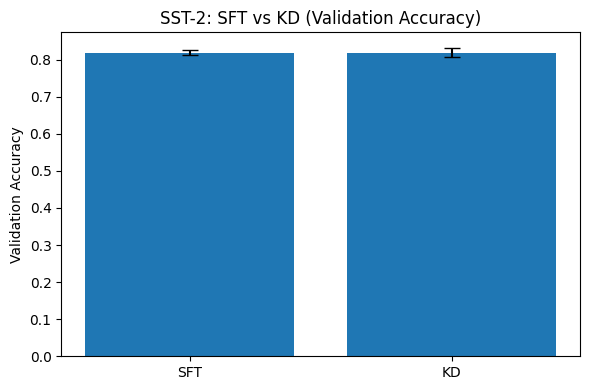

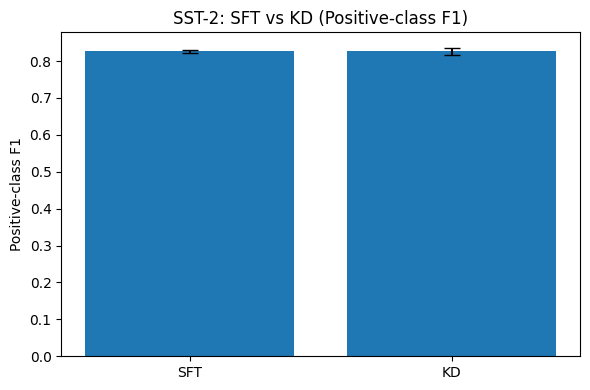

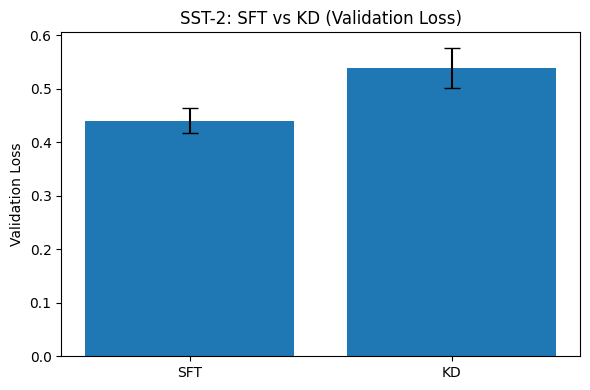

Plots and summary saved in: /content/sst2_sft_vs_kd


,metric,SFT_mean,SFT_std,KD_mean,KD_std,KD_minus_SFT
0,accuracy,0.818807,0.006068,0.818807,0.013025,0.000000
1,f1_positive_class_1,0.826360,0.004477,0.826326,0.009716,-0.000035
2,validation_loss,0.440451,0.022951,0.539268,0.037315,0.098817


In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

OUT = "/content/sst2_sft_vs_kd"
os.makedirs(OUT, exist_ok=True)

df = pd.read_csv(
    os.path.join(OUT, "sst2_sft_kd_results.csv")
)

metrics = {
    "accuracy": "Validation Accuracy",
    "f1_positive_class_1": "Positive-class F1",
    "validation_loss": "Validation Loss"
}

# Plot each metric as mean ± standard deviation across 3 seeds
summary_rows = []

for metric, title in metrics.items():
    stats = df.groupby("method")[metric].agg(["mean", "std"])
    methods = ["SFT", "KD"]

    means = [stats.loc[m, "mean"] for m in methods]
    stds = [stats.loc[m, "std"] for m in methods]

    summary_rows.append({
        "metric": metric,
        "SFT_mean": means[0],
        "SFT_std": stds[0],
        "KD_mean": means[1],
        "KD_std": stds[1],
        "KD_minus_SFT": means[1] - means[0]
    })

    plt.figure(figsize=(6, 4))
    plt.bar(methods, means, yerr=stds, capsize=6)
    plt.ylabel(title)
    plt.title(f"SST-2: SFT vs KD ({title})")
    plt.tight_layout()

    path = os.path.join(OUT, f"{metric}_comparison.png")
    plt.savefig(path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()

summary_df = pd.DataFrame(summary_rows)
summary_df.to_csv(
    os.path.join(OUT, "sst2_metric_summary.csv"), index=False
)

print("Plots and summary saved in:", OUT)
display(summary_df)

In [ ]:
import os

OUT = "/content/sst2_sft_vs_kd"

for filename in [
    "sst2_sft_kd_results.csv",
    "sst2_metric_summary.csv",
    "accuracy_comparison.png",
    "f1_positive_class_1_comparison.png",
    "validation_loss_comparison.png"
]:
    path = os.path.join(OUT, filename)
    print(("FOUND  " if os.path.exists(path) else "MISSING"), filename)

FOUND   sst2_sft_kd_results.csv
FOUND   sst2_metric_summary.csv
FOUND   accuracy_comparison.png
FOUND   f1_positive_class_1_comparison.png
FOUND   validation_loss_comparison.png
